# Skin to CAD: segment, fit, hand off as STEP

A triangle skin -- an STL from a scan or a 3-D-printing download -- is thousands of
flat facets a CAD tool cannot dimension or edit. meshio++ does the mesh-side half of
reverse engineering it with no CAD kernel in the loop, and the CAD half through an
optional OpenCASCADE backend:

- **`segment`** groups the facets into smooth patches bounded by the feature edges,
  with a curvature test that separates a fillet from the faces it is tangent to;
- **`fit_primitives`** fits a plane, sphere, cylinder, cone or torus to each patch and
  reports the residual -- a recovered radius or axis is a measurement;
- the **`step`** writer hands the closed skin to CAD as a faceted solid;
- **`fit_cad`** (a core built with `-DMESHIOPLUSPLUS_WITH_OCCT=ON`) turns the fitted
  patches into analytic CAD faces, sewn into a checked solid and written as STEP.

The part here is a noisy, tessellated turned part with every primitive type in it.
See [skin to CAD](../../doc/cad_fit.md).

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
os.environ.setdefault('VTK_DEFAULT_OPENGL_WINDOW', 'vtkEGLRenderWindow')  # no X server
import meshioplusplus as mp  # noqa: E402

# Head-less, static rendering (no display / live server needed).
pv.OFF_SCREEN = True
pv.set_jupyter_backend('static')
TMP = tempfile.mkdtemp()
DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')
TYPES = ['none', 'plane', 'sphere', 'cylinder', 'cone', 'torus']
TYPE_COLORS = ['#888888', '#4c78a8', '#f58518', '#54a24b', '#e45756', '#b279a2']


def to_grid(mesh):
    '''A PyVista grid of a meshio++ mesh, through a temporary .vtu.'''
    target = os.path.join(TMP, 'render.vtu')
    mp.write(target, mesh)
    return pv.read(target)


def render(mesh, title, scalars=None, cmap='tab10', clim=None, annotations=None, save=None,
           view=(1.0, -1.6, 0.9)):
    '''Render with PyVista, or the points with matplotlib when GL is unavailable.'''
    fig, ax = plt.subplots(figsize=(9, 6))
    try:
        grid = to_grid(mesh)
        pl = pv.Plotter(off_screen=True, window_size=(1000, 720))
        kwargs = {'show_edges': True, 'edge_color': '#333333', 'line_width': 0.2}
        if scalars is not None:
            bar = {'title': scalars, 'vertical': True, 'position_x': 0.86,
                   'position_y': 0.15, 'height': 0.7, 'width': 0.06}
            if annotations:
                bar['n_labels'] = 0
            kwargs.update(scalars=scalars, cmap=cmap, clim=clim, categories=True,
                          annotations=annotations, scalar_bar_args=bar)
        else:
            kwargs['color'] = '#2ec4b6'
        pl.add_mesh(grid, **kwargs)
        pl.view_vector(view, viewup=(0, 0, 1))
        pl.reset_camera()
        pl.camera.zoom(1.15)
        img = pl.screenshot(return_img=True)
        pl.close()
        ax.imshow(img)
        if save:
            try:
                os.makedirs(DOC_IMAGES, exist_ok=True)
                plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
            except Exception as exc:  # pragma: no cover - read-only checkout
                print('doc image not written:', exc)
    except Exception as exc:  # pragma: no cover - head-less GL fallback
        print('PyVista render skipped:', exc)
        p = np.asarray(mesh.points)
        ax.scatter(p[:, 0], p[:, 2], s=1)
    ax.set_title(title)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

## A noisy turned part

A surface of revolution closed by two triangle fans: a flat **base**, a **cylinder**
wall, a toroidal **fillet** tangent to the wall and to a flat **shoulder**, a
**cone**, and a shallow spherical **dome**. The base, shoulder, cone and dome meet
their neighbours at creases; the fillet meets the wall and the shoulder tangentially,
so only its curvature tells it apart. Every point is moved by up to `1e-3`, a scan's
noise.

points: 2178  cells: 2240
{'boundary_edges': 0, 'non_manifold_edges': 0, 'inconsistent_pairs': 0, 'degenerate_triangles': 0, 'watertight': True}


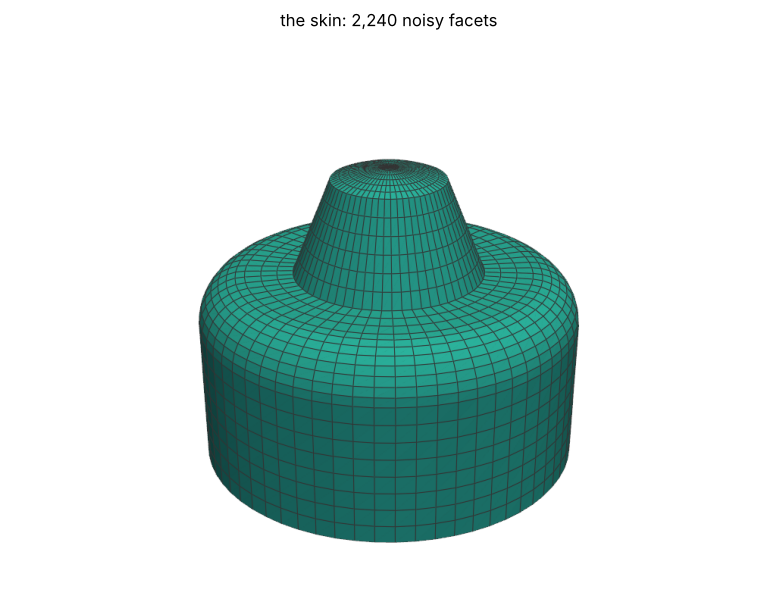

In [2]:
def turned_part(n=64, noise=0.0, seed=7):
    prof = [(2.0 * i / 4, 0.0) for i in range(1, 5)]                       # base
    prof += [(2.0, 1.5 * i / 8) for i in range(1, 9)]                       # wall
    prof += [(1.5 + 0.5 * np.cos(a), 1.5 + 0.5 * np.sin(a))                 # fillet
             for a in np.linspace(0.0, np.pi / 2, 9)[1:]]
    prof += [(1.5 - 0.5 * i / 3, 2.0) for i in range(1, 4)]                 # shoulder
    prof += [(1.0 - 0.4 * i / 6, 2.0 + 1.0 * i / 6) for i in range(1, 7)]   # cone
    zc, big_r = 1.625, 1.5                                                   # dome
    a0 = np.arcsin(0.6 / big_r)
    prof += [(big_r * np.sin(a), zc + big_r * np.cos(a)) for a in np.linspace(a0, 0.0, 7)[1:-1]]
    pts = [[0.0, 0.0, 0.0]]
    for r, z in prof:
        for k in range(n):
            t = 2.0 * np.pi * k / n
            pts.append([r * np.cos(t), r * np.sin(t), z])
    top = len(pts)
    pts.append([0.0, 0.0, zc + big_r])
    ring = lambda i, k: 1 + i * n + (k % n)  # noqa: E731
    last = len(prof) - 1
    tris = [[0, ring(0, k + 1), ring(0, k)] for k in range(n)]
    tris += [[top, ring(last, k), ring(last, k + 1)] for k in range(n)]
    quads = [[ring(i, k), ring(i, k + 1), ring(i + 1, k + 1), ring(i + 1, k)]
             for i in range(last) for k in range(n)]
    pts = np.array(pts)
    if noise:
        pts = pts + noise * np.random.default_rng(seed).uniform(-1.0, 1.0, pts.shape)
    return mp.Mesh(pts, [('triangle', np.array(tris)), ('quad', np.array(quads))])


part = turned_part(noise=1e-3)
print('points:', len(part.points), ' cells:', sum(len(c.data) for c in part.cells))
print(mp.surface_watertight_check(part))
render(part, 'the skin: 2,240 noisy facets')

## Segment

The feature edges alone find four patches: the fillet joins the wall and the shoulder,
because nothing creases between them. `curvature_tolerance` compares each cell's
curvature estimate (about the larger principal curvature: `1/r` on the wall, `1/0.5`
on the fillet, `0` on the planes) with the mean of the patch it would join; the noise
makes a few slivers near the poles, which `min_patch_cells` folds back in.

creases only     : 4 patches
with curvature   : {'num_patches': 6, 'num_merged': 85, 'num_feature_edges': 192, 'num_boundary_edges': 0, 'num_non_manifold_edges': 0}
patch sizes      : [256, 384, 512, 512, 192, 384]
adjacency (a, b, shared edges):
[[ 0  2 64]
 [ 1  5 64]
 [ 2  3 64]
 [ 3  4 64]
 [ 4  5 64]]


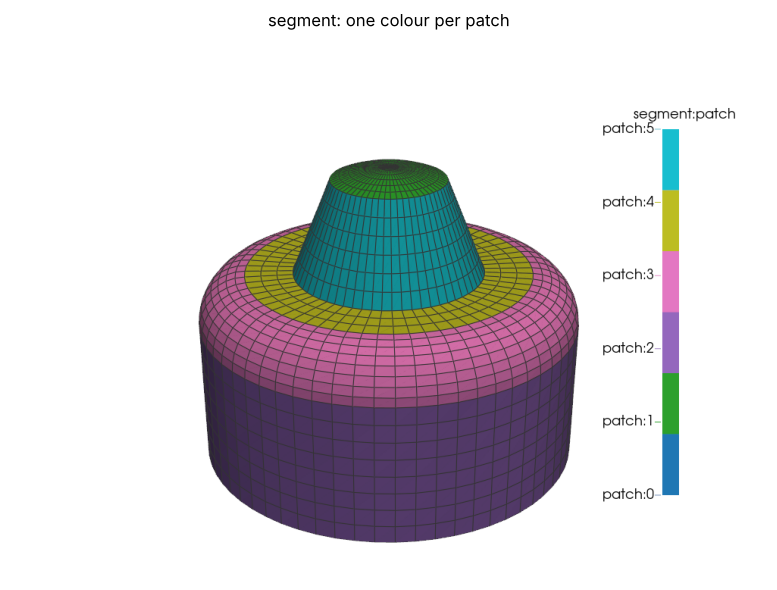

In [3]:
creases_only = mp.segment(part, return_report=True)[1]
print('creases only     :', creases_only['num_patches'], 'patches')

seg, report = mp.segment(part, curvature_tolerance=1.0, min_patch_cells=20, return_report=True)
print('with curvature   :', report)
print('patch sizes      :', np.bincount(np.concatenate(seg.cell_data['segment:patch'])).tolist())
print('adjacency (a, b, shared edges):')
print(seg.field_data['segment:adjacency'])
patches = {k: f'patch:{k}' for k in range(report['num_patches'])}
render(seg, 'segment: one colour per patch', scalars='segment:patch',
       annotations=patches, save='skin_to_cad_patches')

## Fit primitives

Each patch is fitted with every type, refined by Levenberg-Marquardt on the orthogonal
distance, and the simplest type within tolerance (here `2e-3` of the patch's diagonal)
wins. The parameters are the measurement: the wall's radius is 2, the fillet a torus of
major radius 1.5 and minor radius 0.5, the cone's half-angle 21.8 degrees, the dome a
sphere of radius 1.5 -- recovered through the noise, with the residual to prove it.

In [4]:
fit, fit_report = mp.fit_primitives(seg, tolerance=2e-3, return_report=True)
print(fit_report)
fd = fit.field_data
print(f"{'patch':>5} {'type':>9} {'rms':>9}  parameters")
for pid, t, p, rms in zip(fd['fit:patch_id'], fd['fit:patch_type'],
                          fd['fit:patch_params'], fd['fit:patch_rms']):
    name = TYPES[t]
    if name == 'plane':
        what = f'normal {np.round(p[3:6], 3)}'
    elif name == 'sphere':
        what = f'centre {np.round(p[:3], 3)}, radius {p[6]:.4f}'
    elif name == 'cylinder':
        what = f'axis {np.round(p[3:6], 3)}, radius {p[6]:.4f}'
    elif name == 'cone':
        what = f'apex {np.round(p[:3], 3)}, half-angle {p[8]:.2f} deg'
    else:
        what = f'major {p[6]:.4f}, minor {p[7]:.4f}'
    print(f'{pid:>5} {name:>9} {rms:9.2e}  {what}')

{'num_patches': 6, 'num_plane': 2, 'num_sphere': 1, 'num_cylinder': 1, 'num_cone': 1, 'num_torus': 1, 'num_unfitted': 0}
patch      type       rms  parameters
    0     plane  5.81e-04  normal [-0.  0. -1.]
    1    sphere  5.52e-04  centre [-0.    -0.     1.624], radius 1.5006
    2  cylinder  5.78e-04  axis [-0. -0.  1.], radius 2.0000
    3     torus  5.70e-04  major 1.5001, minor 0.4998
    4     plane  5.30e-04  normal [-0.  0.  1.]
    5      cone  5.77e-04  apex [0.  0.  4.5], half-angle 21.80 deg


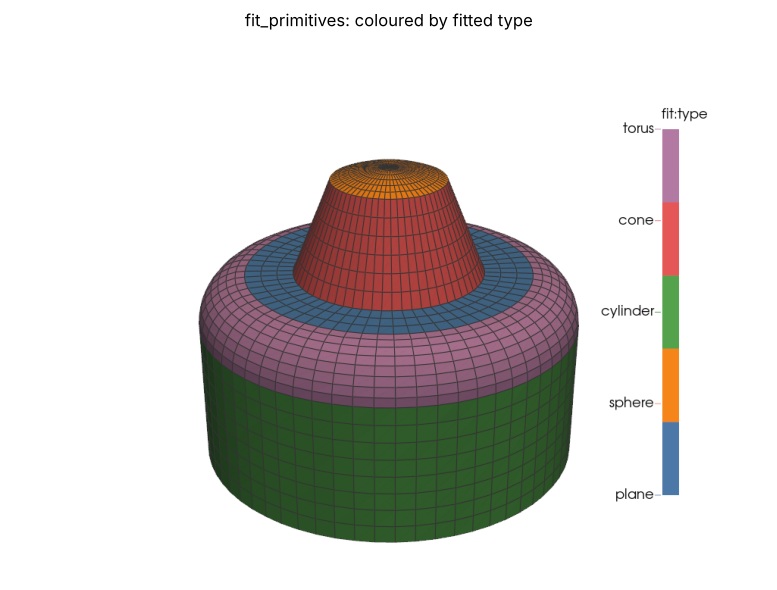

In [5]:
annotations = {i: TYPES[i] for i in range(1, 6)}
render(fit, 'fit_primitives: coloured by fitted type', scalars='fit:type',
       cmap=TYPE_COLORS[1:], clim=[1, 5], annotations=annotations, save='skin_to_cad_fits')

## A fit that does not hold is reported, not rounded

With the tolerance tighter than the noise, nothing is accepted: every patch comes back
as `none` with its best residual, so a downstream tool never mistakes noise for a
primitive.

In [6]:
tight = mp.fit_primitives(seg, tolerance=1e-5, return_report=True)[1]
print(tight)

{'num_patches': 6, 'num_plane': 0, 'num_sphere': 0, 'num_cylinder': 0, 'num_cone': 0, 'num_torus': 0, 'num_unfitted': 6}


## Hand off as STEP

The `step` writer hands the closed skin to CAD as a B-rep solid with no CAD kernel. With
`faces="facet"` it is one planar `ADVANCED_FACE` per facet (non-planar noisy quads are
fanned into triangles); by default it merges coplanar facets into one face and, on a skin
`segment` and `fit_primitives` annotated, writes every accepted patch as one face on its
fitted surface -- here the noisy part's planes, cylinder, torus, cone and sphere --
bounded by circles where a plane meets the wall, the cone or the dome. A patch whose
points stray further than the tolerance from its surface would be written as planar
faces instead. See [STEP](../../doc/formats/step.md).

In [7]:
for label, mesh, faces in (('one face per facet', part, 'facet'), ('fitted faces', fit, 'auto')):
    step_path = os.path.join(TMP, f'turned_part_{faces}.step')
    mp.write(step_path, mesh, faces=faces)
    text = open(step_path).read()
    counts = {e: text.count('=' + e + '(') for e in
              ('ADVANCED_FACE', 'PLANE', 'CYLINDRICAL_SURFACE', 'CONICAL_SURFACE',
               'SPHERICAL_SURFACE', 'TOROIDAL_SURFACE', 'CIRCLE', 'EDGE_CURVE')}
    print(f'{label:>20}:', counts)

  one face per facet: {'ADVANCED_FACE': 4352, 'PLANE': 4352, 'CYLINDRICAL_SURFACE': 0, 'CONICAL_SURFACE': 0, 'SPHERICAL_SURFACE': 0, 'TOROIDAL_SURFACE': 0, 'CIRCLE': 0, 'EDGE_CURVE': 6528}
        fitted faces: {'ADVANCED_FACE': 6, 'PLANE': 2, 'CYLINDRICAL_SURFACE': 1, 'CONICAL_SURFACE': 1, 'SPHERICAL_SURFACE': 1, 'TOROIDAL_SURFACE': 1, 'CIRCLE': 5, 'EDGE_CURVE': 5}


## Analytic CAD faces with `fit_cad`

`fit_cad` builds the solid from the fitted patches. With the optional OpenCASCADE backend
each accepted patch becomes one face on its fitted surface, trimmed by the patch boundary:
exact circles where a plane meets the cylinder, the cone or the dome, B-splines where the
fillet meets the wall and the shoulder tangentially. OpenCASCADE sews and checks the
solid, and any face it rejects, or that strays further than the tolerance from the skin,
would come back faceted and be counted in `num_demoted`. The report compares the solid
with the skin: its volume ratio and the Hausdorff deviation of its re-meshed surface.
Without OpenCASCADE, `fit_cad` runs its kernel-free native backend, the `step` writer's
fitted faces above. See [fit CAD](../../doc/fit_cad.md).

occt {'valid': True, 'num_faces': 6, 'num_plane': 2, 'num_sphere': 1, 'num_cylinder': 1, 'num_cone': 1, 'num_torus': 1, 'num_faceted_faces': 0, 'num_demoted': 0, 'num_exact_edges': 5, 'num_approx_edges': 5}
volume ratio 1.00218, max deviation 8.91e-03 (tolerance 3.51e-02)
               PLANE: 2
 CYLINDRICAL_SURFACE: 1
     CONICAL_SURFACE: 1
   SPHERICAL_SURFACE: 1
    TOROIDAL_SURFACE: 1
       ADVANCED_FACE: 6


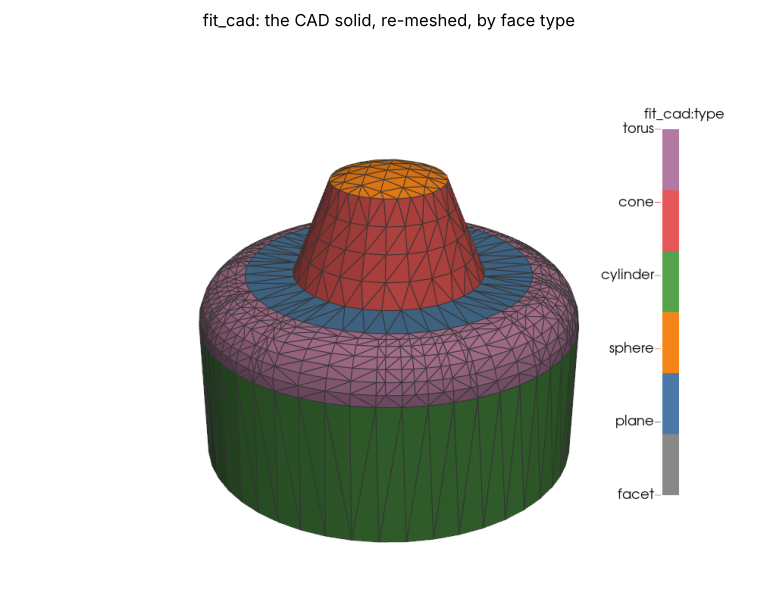

In [8]:
from meshioplusplus._fit_cad import has_occt

if has_occt():
    cad_path = os.path.join(TMP, 'turned_part_cad.step')
    solid, cad = mp.fit_cad(fit, cad_path, return_report=True)
    print(cad['backend'], {k: cad[k] for k in ('valid', 'num_faces', 'num_plane', 'num_sphere', 'num_cylinder',
                                'num_cone', 'num_torus', 'num_faceted_faces', 'num_demoted',
                                'num_exact_edges', 'num_approx_edges')})
    print(f"volume ratio {cad['volume_ratio']:.5f}, max deviation {cad['max_deviation']:.2e}"
          f" (tolerance {cad['tolerance']:.2e})")
    text = open(cad_path).read()
    for entity in ('PLANE', 'CYLINDRICAL_SURFACE', 'CONICAL_SURFACE', 'SPHERICAL_SURFACE',
                   'TOROIDAL_SURFACE', 'ADVANCED_FACE'):
        print(f'{entity:>20}: {text.count("= " + entity + "(")}')
    render(solid, 'fit_cad: the CAD solid, re-meshed, by face type', scalars='fit_cad:type',
           cmap=TYPE_COLORS, clim=[0, 5], annotations={0: 'facet', **{i: TYPES[i] for i in range(1, 6)}},
           save='fit_cad_solid')
else:
    solid, cad = mp.fit_cad(fit, os.path.join(TMP, 'turned_part_cad.step'), return_report=True)
    print('native backend (no OpenCASCADE):', {k: cad[k] for k in ('valid', 'num_faces', 'num_plane',
          'num_sphere', 'num_cylinder', 'num_cone', 'num_torus', 'num_demoted')})

## Curled patches, fillets and threads

Three kinds of patch no primitive explains get more than a freeform face:

- a patch that folds over both its best-fit plane and an unrolled cylinder -- here a band
  closed around its axis, whose radius waves along it -- is **split** into pieces that do
  unroll, each its own B-spline face under a new patch label;
- a patch running between two analytic faces is tried as a constant-radius **rolling-ball
  fillet**: the pipe of the fitted radius around the spine where the two surfaces, offset
  by it, meet -- here the foot of a leaning boss, a fillet swept along an ellipse;
- a patch beside a cylinder or cone is tried as a straight **thread flank**, a ruled
  helicoid about its axis -- here both flanks of a trapezoidal thread.

`num_split_patches`, `num_fillet` and `num_helical` count them; `fit_cad:type` is 6 for a
freeform B-spline, 7 for a fillet and 8 for a thread face. See
[fit CAD](../../doc/fit_cad.md#fillets-blends-and-threads).

In [9]:
def closed_revolve(prof, z0, z1, n):
    pts = [[0.0, 0.0, z0]] + [[r * np.cos(2 * np.pi * k / n), r * np.sin(2 * np.pi * k / n), z]
                              for r, z in prof for k in range(n)] + [[0.0, 0.0, z1]]
    ring = lambda i, k: 1 + i * n + (k % n)  # noqa: E731
    last, top = len(prof) - 1, len(pts) - 1
    tris = [[0, ring(0, k + 1), ring(0, k)] for k in range(n)]
    tris += [[top, ring(last, k), ring(last, k + 1)] for k in range(n)]
    for i in range(last):
        for k in range(n):
            tris += [[ring(i, k), ring(i, k + 1), ring(i + 1, k + 1)],
                     [ring(i, k), ring(i + 1, k + 1), ring(i + 1, k)]]
    return mp.Mesh(np.array(pts), [('triangle', np.array(tris))])


def wavy_capped(n=96, m=64):
    '''A capped band whose radius waves along z: r = 1 + 0.15 sin(2 pi z).'''
    prof = [(i / 3, 0.0) for i in range(1, 4)]
    prof += [(1 + 0.15 * np.sin(4 * np.pi * i / m), 2 * i / m) for i in range(1, m + 1)]
    return closed_revolve(prof + [(2 / 3, 2.0), (1 / 3, 2.0)], 0.0, 2.0, n)


class Skin:
    '''Triangles wound along an expected outward direction.'''
    def __init__(self):
        self.pts, self.tris = [], []

    def add(self, p):
        self.pts.append(list(map(float, p)))
        return len(self.pts) - 1

    def tri(self, a, b, c, out):
        p, q, r = (np.asarray(self.pts[i]) for i in (a, b, c))
        self.tris.append([a, b, c] if np.dot(np.cross(q - p, r - p), out) >= 0 else [a, c, b])

    def quads(self, ra, rb, out):
        for i in range(len(ra)):
            j = (i + 1) % len(ra)
            self.tri(ra[i], ra[j], rb[j], out(i))
            self.tri(ra[i], rb[j], rb[i], out(i))

    def mesh(self):
        return mp.Mesh(np.array(self.pts), [('triangle', np.array(self.tris))])


def inclined_boss(alpha=20.0, r=0.6, rf=0.2, h=1.5, plate=1.6, t=0.4, n=96, k=8):
    '''A boss leaning alpha degrees on a round plate, its foot rounded by a
    concave fillet of radius rf: a canal surface along an ellipse.'''
    al = np.radians(alpha)
    ax, e1, ez = np.array([np.sin(al), 0, np.cos(al)]), np.array([np.cos(al), 0, -np.sin(al)]), np.array([0, 0, 1.0])
    b, rows, centre, unit, foot = Skin(), [[] for _ in range(k + 1)], [], [], []
    for i in range(n):
        th = 2 * np.pi * i / n
        u = np.cos(th) * e1 + np.array([0, np.sin(th), 0])
        hh = (rf + (r + rf) * np.sin(al) * np.cos(th)) / np.cos(al)
        c = hh * ax + (r + rf) * u
        centre.append(c), unit.append(u), foot.append(hh)
        w = np.arccos(np.clip(u[2], -1, 1))
        for j in range(k + 1):
            s = j / k
            rows[j].append(b.add(c - rf * (np.sin(s * w) * u + np.sin((1 - s) * w) * ez) / np.sin(w)))
    for j in range(k):
        b.quads(rows[j], rows[j + 1], lambda i, j=j: centre[i] - b.pts[rows[j][i]])
    prev = rows[k]
    for j in range(1, 9):
        row = [b.add((foot[i] + (h - foot[i]) * j / 8) * ax + r * unit[i]) for i in range(n)]
        b.quads(prev, row, lambda i: unit[i])
        prev = row
    top = b.add(h * ax)
    for i in range(n):
        b.tri(top, prev[i], prev[(i + 1) % n], ax)
    inner = rows[0]
    psi = [np.arctan2(b.pts[v][1], b.pts[v][0]) for v in inner]
    rho = [np.hypot(*b.pts[v][:2]) for v in inner]
    for j in range(1, 7):
        row = [b.add([(rho[i] + (plate - rho[i]) * j / 6) * np.cos(psi[i]),
                      (rho[i] + (plate - rho[i]) * j / 6) * np.sin(psi[i]), 0]) for i in range(n)]
        b.quads(inner, row, lambda i: ez)
        inner = row
    lower = [b.add([plate * np.cos(p), plate * np.sin(p), -t]) for p in psi]
    b.quads(inner, lower, lambda i: np.array([np.cos(psi[i]), np.sin(psi[i]), 0]))
    bottom = b.add([0, 0, -t])
    for i in range(n):
        b.tri(bottom, lower[i], lower[(i + 1) % n], -ez)
    return b.mesh()


def threaded_rod(pitch=0.5, r0=0.8, r1=1.0, turns=3, n=64):
    '''A trapezoidal thread, r = f(z - K theta): root and crest cylinders,
    both flanks ruled helicoids, closed by two shallow end fans.'''
    k, w, rad, at = pitch / (2 * np.pi), [], [], 0.0
    for s, (seg, sub) in enumerate(zip([0.26, 0.24, 0.26, 0.24], [2, 3, 2, 3])):
        for i in range(sub):
            w.append(at + seg * pitch * i / sub)
            rad.append([r0, r0 + (r1 - r0) * i / sub, r1, r1 - (r1 - r0) * i / sub][s])
        at += seg * pitch
    per, b = len(w), Skin()
    rows = per * turns
    ids = [[b.add([rad[j % per] * np.cos(2 * np.pi * i / n), rad[j % per] * np.sin(2 * np.pi * i / n),
                   w[j % per] + pitch * (j // per) + k * 2 * np.pi * i / n]) for j in range(rows + 1)]
           for i in range(n)]
    node = lambda i, j: ids[i][j] if i < n else (ids[0][j + per] if j + per <= rows else -1)  # noqa: E731
    for i in range(n):
        for j in range(rows):
            a, bb, c, d = node(i, j), node(i + 1, j), node(i + 1, j + 1), node(i, j + 1)
            if bb < 0 or c < 0:
                continue
            pa, pd = np.asarray(b.pts[a]), np.asarray(b.pts[d])
            ra, rd = np.hypot(*pa[:2]), np.hypot(*pd[:2])
            out = np.array([pa[0] / ra, pa[1] / ra, -1.0 if rd > ra + 1e-12 else (1.0 if rd < ra - 1e-12 else 0.0)])
            b.tri(a, bb, c, out), b.tri(a, c, d, out)

    def fan(loop, reverse):
        zs = [b.pts[v][2] for v in loop]
        c = b.add([0, 0, max(zs) + pitch if reverse else min(zs) - pitch])
        for i in range(len(loop)):
            p, q = loop[i], loop[(i + 1) % len(loop)]
            b.tris.append([c, q, p] if reverse else [c, p, q])

    fan([node(i, 0) for i in range(n)] + [node(0, j) for j in range(per, 0, -1)], True)
    fan([node(i, rows) for i in range(n)] + [node(n - 1, j) for j in range(rows - 1, rows - per - 1, -1)], False)
    return b.mesh()

  a band closed around its axis, split: valid True, 4 faces -- split 2, B-spline 2, fillet 0, thread 0, faceted 0; deviation 2.7e-03 (tolerance 8.5e-03)


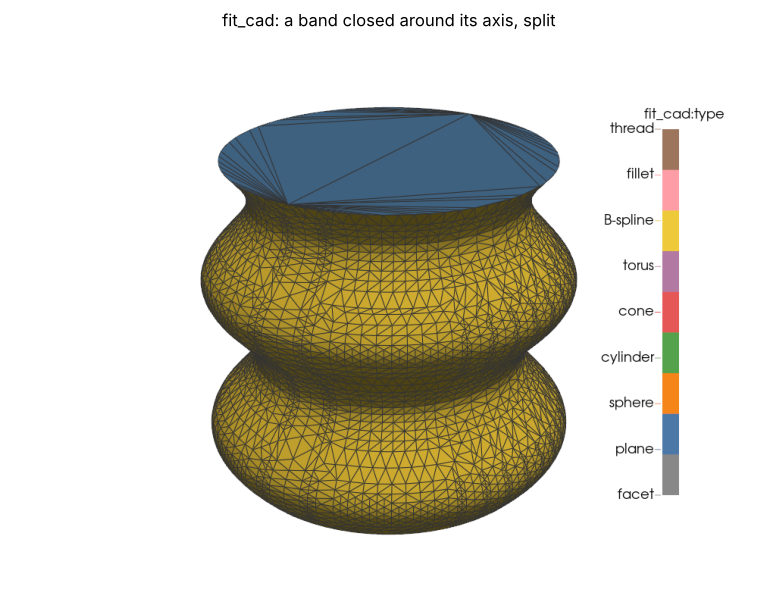

       a fillet swept along an ellipse: valid True, 6 faces -- split 0, B-spline 0, fillet 1, thread 0, faceted 0; deviation 7.7e-03 (tolerance 1.4e-02)


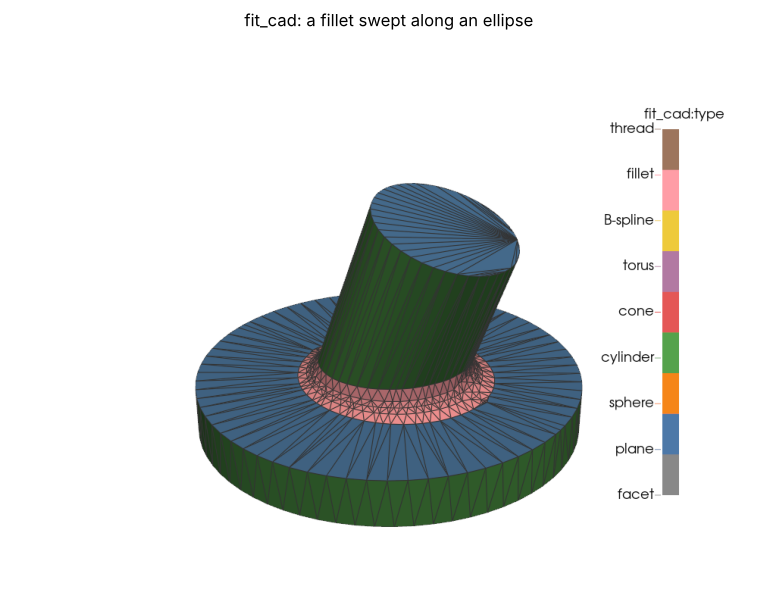

                  a trapezoidal thread: valid True, 137 faces -- split 0, B-spline 0, fillet 0, thread 2, faceted 128; deviation 3.2e-03 (tolerance 9.8e-03)


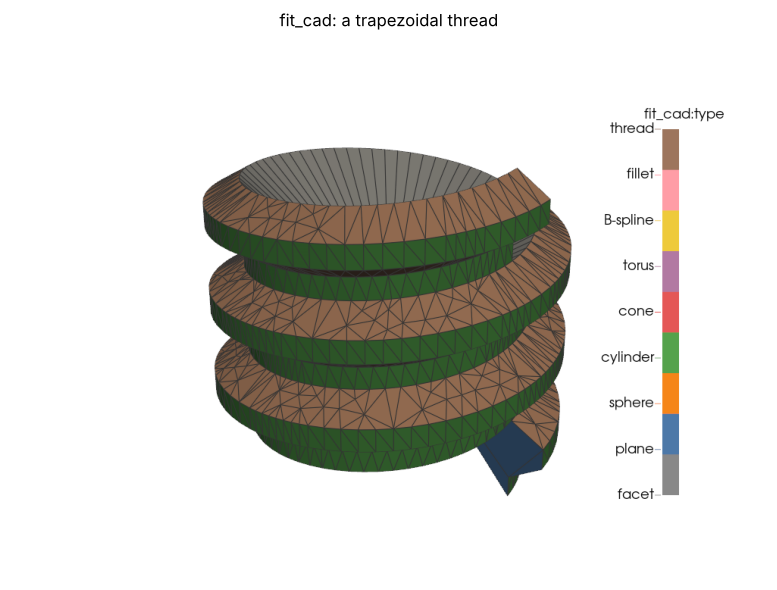

In [10]:
FEATURE_COLORS = TYPE_COLORS + ['#eeca3b', '#ff9da6', '#9d755d']
FEATURES = {0: 'facet', **{i: TYPES[i] for i in range(1, 6)}, 6: 'B-spline', 7: 'fillet', 8: 'thread'}
cases = [('a band closed around its axis, split', wavy_capped(), 0.0, 'fit_cad_split'),
         ('a fillet swept along an ellipse', inclined_boss(), 3.0, 'fit_cad_fillet'),
         ('a trapezoidal thread', threaded_rod(), 0.0, 'fit_cad_thread')]
if has_occt():
    for title, skin, ctol, save in cases:
        fitted = mp.fit_primitives(mp.segment(skin, curvature_tolerance=ctol))
        solid, cad = mp.fit_cad(fitted, return_report=True)
        print(f"{title:>38}: valid {cad['valid']}, {cad['num_faces']} faces -- "
              f"split {cad['num_split_patches']}, B-spline {cad['num_bspline']}, "
              f"fillet {cad['num_fillet']}, thread {cad['num_helical']}, "
              f"faceted {cad['num_faceted_faces']}; deviation {cad['max_deviation']:.1e}"
              f" (tolerance {cad['tolerance']:.1e})")
        render(solid, f'fit_cad: {title}', scalars='fit_cad:type', cmap=FEATURE_COLORS,
               clim=[0, 8], annotations=FEATURES, save=save)
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON.')

## Fillets of varying radius, blends and rounded threads

What one radius, two analytic neighbours or a straight flank about a neighbouring cylinder
cannot explain is fitted too:

- a **fillet whose radius varies** along it gets one ball radius per vertex, fitted as a law
  along the edge, and a face through the cross-sections of the ball family -- here a block's
  edge rounded by a ball shrinking from 0.3 to 0.2;
- a patch between two fitted faces, one of them a freeform B-spline, is tried as a
  **rolling-ball blend** against them once the freeform faces exist -- here a bar whose wavy
  top and leaning front are both freeform;
- a **thread of any profile** finds its screw from its own facets (the screw motion most
  nearly tangent to the patch) when no cylinder or cone gives an axis -- here a thread whose
  root and crest are rounded arcs, with no cylinder anywhere.

`num_variable_fillet`, `num_blend` and `num_rounded_thread` count them among the fillet
and thread faces.

In [11]:
def loft(loops, centres):
    '''Rows of cross-section loops (points with an outward hint, None pointing away from
    the row's centre) as quads, the two ends closed by fans to the end loops' centroids.'''
    b = Skin()
    ids = [[b.add(p) for p, _ in loop] for loop in loops]
    count = len(ids[0])
    for i in range(len(loops) - 1):
        for j in range(count):
            out = loops[i][j][1]
            out = np.asarray(b.pts[ids[i][j]]) - centres[i] if out is None else np.asarray(out)
            jn = (j + 1) % count
            b.tri(ids[i][j], ids[i + 1][j], ids[i + 1][jn], out)
            b.tri(ids[i][j], ids[i + 1][jn], ids[i][jn], out)
    for i, sign in ((0, -1.0), (len(loops) - 1, 1.0)):
        mid = b.add(np.mean([b.pts[v] for v in ids[i]], axis=0))
        for j in range(count):
            b.tri(mid, ids[i][j], ids[i][(j + 1) % count], np.array([sign, 0, 0]))
    return b.mesh()


def variable_fillet_block(length=2.0, rm=0.25, ra=0.05, n=48, k=16, m=6):
    '''The unit-section block along x whose edge at y = z = 1 is rounded by a ball of radius
    r(x) = rm + ra cos(pi x / length): each fillet row is the exact characteristic circle.'''
    loops, centres = [], []
    for i in range(n + 1):
        x = length * i / n
        r = rm + ra * np.cos(np.pi * x / length)
        dr = -ra * np.pi / length * np.sin(np.pi * x / length)
        c, cd = np.array([x, 1 - r, 1 - r]), np.array([1.0, -dr, -dr])
        delta = -r * dr / np.linalg.norm(cd)
        cc, rho = c + delta * cd / np.linalg.norm(cd), np.sqrt(r * r - delta * delta)
        a = (np.array([x, 1.0, 1 - r]) - cc) / rho
        b2 = np.array([x, 1 - r, 1.0]) - cc
        bv = b2 - np.dot(b2, a) * a
        bv /= np.linalg.norm(bv)
        om = np.arctan2(np.dot(b2, bv), np.dot(b2, a))
        loop = [([x, j / m, 0], [0, 0, -1]) for j in range(m)]
        loop += [([x, 1, (1 - r) * j / m], [0, 1, 0]) for j in range(m)]
        loop += [(cc + rho * (np.cos(om * j / k) * a + np.sin(om * j / k) * bv), None) for j in range(k)]
        loop += [([x, (1 - r) * (1 - j / m), 1], [0, 0, 1]) for j in range(m)]
        loop += [([x, 0, 1 - j / m], [0, -1, 0]) for j in range(m)]
        loops.append(loop), centres.append(c)
    return loft(loops, centres)


def wavy_bar(length=3.0, wave=0.06, twist=3.0, r=0.2, n=96, k=8, m=8):
    '''A bar whose top waves and whose front leans in and out, both freeform and tangent
    to a ball of radius r rolling along (x, 0, wave cos(4 pi x / length)).'''
    loops, centres = [], []
    for i in range(n + 1):
        x = length * i / n
        c = np.array([x, 0.0, wave * np.cos(4 * np.pi * x / length)])
        t = np.array([1.0, 0.0, -wave * 4 * np.pi / length * np.sin(4 * np.pi * x / length)])
        t /= np.linalg.norm(t)
        side = np.array([0.0, 1.0, 0.0])
        m1 = np.cross(t, side)
        psi = np.radians(twist) * np.sin(2 * np.pi * x / length)
        m2 = np.cos(psi) * side + np.sin(psi) * m1
        q1, q2 = c + r * m1, c + r * m2
        w1, w2 = np.cross(m1, t), np.cross(m2, t)
        w1, w2 = (w1 if w1[1] < 0 else -w1), (w2 if w2[2] < 0 else -w2)
        w1, w2 = w1 - w1[0] / t[0] * t, w2 - w2[0] / t[0] * t
        top, low = q1 + (q1[1] + 1) / -w1[1] * w1, q2 + (q2[2] + 1) / -w2[2] * w2
        corner = np.array([top[0], -1.0, -1.0])
        om = np.arccos(np.clip(np.dot(m1, m2), -1, 1))
        loop = [(corner + (top - corner) * j / m, [0, -1, 0]) for j in range(m)]
        loop += [(top + (q1 - top) * j / m, m1) for j in range(m)]
        loop += [(c + r * (np.sin((1 - j / k) * om) * m1 + np.sin(j / k * om) * m2) / np.sin(om), None)
                 for j in range(k)]
        loop += [(q2 + (low - q2) * j / m, m2) for j in range(m)]
        loop += [(low + (corner - low) * j / m, [0, 0, -1]) for j in range(m)]
        loops.append(loop), centres.append(c)
    return loft(loops, centres)


def rounded_thread_rod(pitch=0.5, r0=0.8, r1=1.0, rr=0.2, turns=3, n=64):
    '''threaded_rod's thread with its root and crest flats replaced by circular arcs of
    radius rr (the crest bulging out, the root in), meeting the flanks at a crease.'''
    half = 0.13 * pitch
    d = np.sqrt(rr * rr - half * half)
    k, w, rad, at = pitch / (2 * np.pi), [], [], 0.0
    for s, (seg, sub) in enumerate(zip([0.26, 0.24, 0.26, 0.24], [4, 3, 4, 3])):
        for i in range(sub):
            x = seg * pitch * i / sub - half
            w.append(at + seg * pitch * i / sub)
            rad.append([r0 + d - np.sqrt(rr * rr - x * x), r0 + (r1 - r0) * i / sub,
                        r1 - d + np.sqrt(rr * rr - x * x), r1 - (r1 - r0) * i / sub][s])
        at += seg * pitch
    per, b = len(w), Skin()
    rows = per * turns
    ids = [[b.add([rad[j % per] * np.cos(2 * np.pi * i / n), rad[j % per] * np.sin(2 * np.pi * i / n),
                   w[j % per] + pitch * (j // per) + k * 2 * np.pi * i / n]) for j in range(rows + 1)]
           for i in range(n)]
    node = lambda i, j: ids[i][j] if i < n else (ids[0][j + per] if j + per <= rows else -1)  # noqa: E731
    for i in range(n):
        for j in range(rows):
            a, bb, c, dd = node(i, j), node(i + 1, j), node(i + 1, j + 1), node(i, j + 1)
            if bb < 0 or c < 0:
                continue
            pa, pd = np.asarray(b.pts[a]), np.asarray(b.pts[dd])
            ra, rd = np.hypot(*pa[:2]), np.hypot(*pd[:2])
            out = np.array([pa[0] / ra, pa[1] / ra, -1.0 if rd > ra + 1e-12 else (1.0 if rd < ra - 1e-12 else 0.0)])
            b.tri(a, bb, c, out), b.tri(a, c, dd, out)

    def fan(loop, reverse):
        zs = [b.pts[v][2] for v in loop]
        c = b.add([0, 0, max(zs) + pitch if reverse else min(zs) - pitch])
        for i in range(len(loop)):
            p, q = loop[i], loop[(i + 1) % len(loop)]
            b.tris.append([c, q, p] if reverse else [c, p, q])

    fan([node(i, 0) for i in range(n)] + [node(0, j) for j in range(per, 0, -1)], True)
    fan([node(i, rows) for i in range(n)] + [node(n - 1, j) for j in range(rows - 1, rows - per - 1, -1)], False)
    return b.mesh()

      a fillet of varying radius: valid True, 7 faces -- B-spline 0, fillet 1 (varying 1, blend 0), thread 0 (rounded 0), faceted 0; deviation 2.1e-03 (tolerance 6.7e-03)


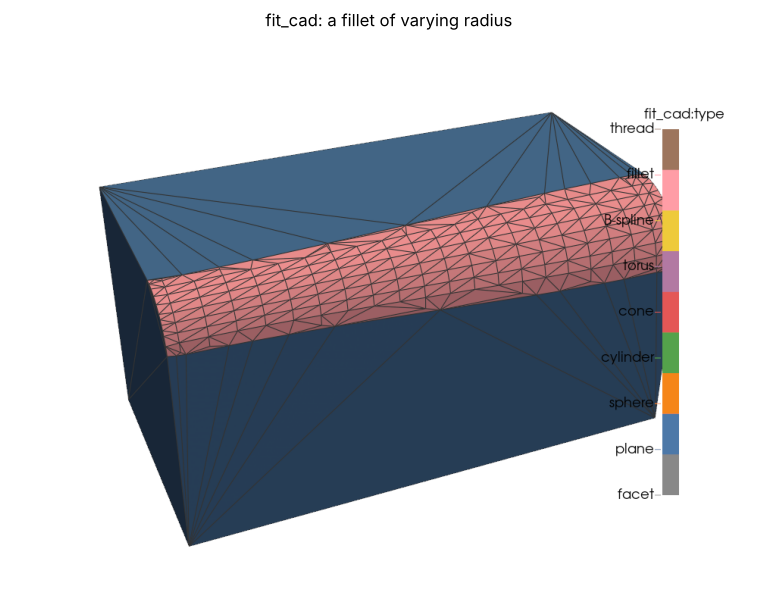

  a blend between freeform faces: valid True, 7 faces -- B-spline 2, fillet 1 (varying 0, blend 1), thread 0 (rounded 0), faceted 0; deviation 5.2e-03 (tolerance 9.8e-03)


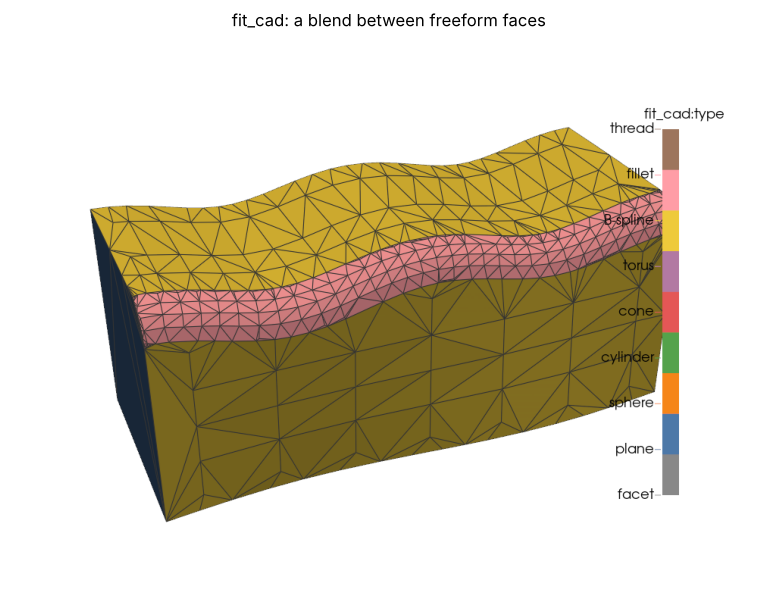

   a rounded thread, no cylinder: valid True, 137 faces -- B-spline 0, fillet 0 (varying 0, blend 0), thread 4 (rounded 2), faceted 128; deviation 2.1e-03 (tolerance 4.3e-03)


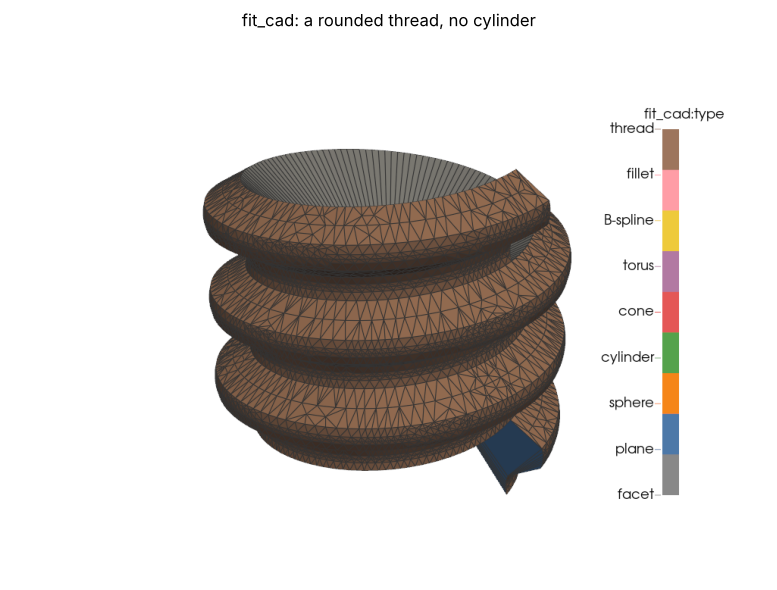

In [12]:
# Seen from the side each rounded edge faces.
cases = [('a fillet of varying radius', variable_fillet_block(), 3.0, 'fit_cad_variable_fillet', (0.6, 1.4, 0.9)),
         ('a blend between freeform faces', wavy_bar(), 3.0, 'fit_cad_blend', (0.6, 1.4, 0.9)),
         ('a rounded thread, no cylinder', rounded_thread_rod(), 0.0, 'fit_cad_rounded_thread', (1.0, -1.6, 0.9))]
if has_occt():
    for title, skin, ctol, save, view in cases:
        fitted = mp.fit_primitives(mp.segment(skin, curvature_tolerance=ctol))
        solid, cad = mp.fit_cad(fitted, return_report=True)
        print(f"{title:>32}: valid {cad['valid']}, {cad['num_faces']} faces -- "
              f"B-spline {cad['num_bspline']}, fillet {cad['num_fillet']} "
              f"(varying {cad['num_variable_fillet']}, blend {cad['num_blend']}), "
              f"thread {cad['num_helical']} (rounded {cad['num_rounded_thread']}), "
              f"faceted {cad['num_faceted_faces']}; deviation {cad['max_deviation']:.1e}"
              f" (tolerance {cad['tolerance']:.1e})")
        render(solid, f'fit_cad: {title}', scalars='fit_cad:type', cmap=FEATURE_COLORS,
               clim=[0, 8], annotations=FEATURES, save=save, view=view)
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON.')

## Chamfers, conic blends, vertex blends and tapered threads

Four more kinds of feature are fitted when the earlier attempts refuse a patch:

- a patch between two analytic faces whose sections across their edge are **straight** is a
  **chamfer**, of constant or varying width (`fit_cad:type` 10) -- here a block's edge cut
  0.3 in from the top and 0.2 to 0.4 down the side;
- one whose sections are **conics** tangent to both faces is a **conic blend** (type 7,
  counted in `num_conic_blend`) -- here every edge of a box that was rounded and then
  scaled unequally, so no edge blend is circular;
- where three or more blends meet, the corner patch is a **vertex blend** (type 9): a plate
  surface tangent to its neighbours along its whole boundary -- the same box's eight
  corners;
- a straight thread flank beside a **cone** is a **tapered thread** (type 8, counted in
  `num_tapered_thread`), and one whose advance grows along the axis a variable-pitch one.

The chamfer and the box carry their faces as `segment:patch`, as a segmentation by labels
would: a conic blend's curvature varies across it, so a curvature tolerance cannot isolate
it from its neighbours.

In [13]:
def labelled(mesh, label):
    mesh.cell_data['segment:patch'] = [np.asarray(label, dtype=np.int64)]
    return mesh


def chamfered_block(length=2.0, d1=0.3, d2a=0.2, d2b=0.4, n=40, k=12, m=6):
    '''The unit-section block along x whose edge at y = z = 1 is cut by a chamfer from 0.3 in
    from the edge on the top to d2(x) down the side, d2 growing linearly from d2a to d2b.'''
    loops, centres = [], []
    for i in range(n + 1):
        x = length * i / n
        d2 = d2a + (d2b - d2a) * x / length
        side, top = np.array([x, 1.0, 1.0 - d2]), np.array([x, 1.0 - d1, 1.0])
        loop = [([x, j / m, 0], [0, 0, -1]) for j in range(m)]
        loop += [([x, 1, (1 - d2) * j / m], [0, 1, 0]) for j in range(m)]
        loop += [(side + (top - side) * j / k, None) for j in range(k)]
        loop += [([x, (1 - d1) * (1 - j / m), 1], [0, 0, 1]) for j in range(m)]
        loop += [([x, 0, 1 - j / m], [0, -1, 0]) for j in range(m)]
        loops.append(loop), centres.append(np.array([x, 1 - d1, 1 - d2]))
    mesh = loft(loops, centres)
    c, e = mesh.points[mesh.cells[0].data].mean(axis=1), 1e-9
    label = np.full(len(c), 6)
    for code, hit in reversed([(0, abs(c[:, 2]) < e), (1, abs(c[:, 1] - 1) < e), (2, abs(c[:, 2] - 1) < e),
                               (3, abs(c[:, 1]) < e), (4, abs(c[:, 0]) < e), (5, abs(c[:, 0] - length) < e)]):
        label[hit] = code
    return labelled(mesh, label)


def rounded_box(r=0.3, scale=(1.0, 1.3, 0.8), nf=4, nb=6):
    '''The cube [-1, 1]^3 with every edge and corner rounded by a ball of radius r, then
    scaled: conic edge blends, and corners that are vertex blends of three of them.'''
    inner, scale = 1.0 - r, np.asarray(scale)
    g = [-(inner + r * np.tan(np.pi / 4 * k / nb)) for k in range(nb, 0, -1)]
    g += [-inner + 2 * inner * k / nf for k in range(nf + 1)]
    g += [inner + r * np.tan(np.pi / 4 * k / nb) for k in range(1, nb + 1)]
    b, ids, label = Skin(), {}, []

    def vertex(x):
        key = tuple(int(round(v * 1e9)) for v in x)
        if key not in ids:
            c = np.clip(x, -inner, inner)
            ids[key] = b.add(scale * (c + r * (x - c) / np.linalg.norm(x - c)))
        return ids[key]

    for a in range(3):
        for sign in (-1.0, 1.0):
            u, v = (a + 1) % 3, (a + 2) % 3
            out = np.eye(3)[a] * sign

            def at(i, j):
                x = np.zeros(3)
                x[a], x[u], x[v] = sign, g[i], g[j]
                return x

            for i in range(len(g) - 1):
                for j in range(len(g) - 1):
                    q = [vertex(at(i, j)), vertex(at(i + 1, j)), vertex(at(i + 1, j + 1)), vertex(at(i, j + 1))]
                    b.tri(q[0], q[1], q[2], out), b.tri(q[0], q[2], q[3], out)
                    c = 0.5 * (at(i, j) + at(i + 1, j + 1))
                    label += [sum(3 ** (2 - t) * (2 if c[t] > inner else 0 if c[t] < -inner else 1)
                                  for t in range(3))] * 2
    return labelled(b.mesh(), label)


def tapered_thread_rod(pitch=0.5, r0=0.8, r1=1.0, taper=0.0625, turns=4, n=64):
    '''threaded_rod's trapezoidal thread cut on a cone whose radius grows by taper per unit
    length: root and crest are helical strips of cones, the flanks tapered helicoids.'''
    w, rad, at = [], [], 0.0
    for s, (seg, sub) in enumerate(zip([0.26, 0.24, 0.26, 0.24], [2, 3, 2, 3])):
        for i in range(sub):
            w.append(at + seg * pitch * i / sub)
            rad.append([r0, r0 + (r1 - r0) * i / sub, r1, r1 - (r1 - r0) * i / sub][s])
        at += seg * pitch
    k, per, b = pitch / (2 * np.pi), len(w), Skin()
    rows = per * turns

    def at_node(i, j):
        th = 2 * np.pi * i / n
        z = w[j % per] + pitch * (j // per) + k * th
        rr = rad[j % per] + taper * z
        return [rr * np.cos(th), rr * np.sin(th), z]

    ids = [[b.add(at_node(i, j)) for j in range(rows + 1)] for i in range(n)]
    node = lambda i, j: ids[i][j] if i < n else (ids[0][j + per] if j + per <= rows else -1)  # noqa: E731
    for i in range(n):
        for j in range(rows):
            a, bb, c, dd = node(i, j), node(i + 1, j), node(i + 1, j + 1), node(i, j + 1)
            if bb < 0 or c < 0:
                continue
            pa, pd = np.asarray(b.pts[a]), np.asarray(b.pts[dd])
            ra, rd = np.hypot(*pa[:2]), np.hypot(*pd[:2])
            # The flank faces up the axis when the radius shrinks along it, down when it grows.
            flank = rad[(j + 1) % per] - rad[j % per]
            out = np.array([pa[0] / ra, pa[1] / ra, -1.0 if flank > 1e-12 else (1.0 if flank < -1e-12 else 0.0)])
            b.tri(a, bb, c, out), b.tri(a, c, dd, out)

    def fan(loop, reverse):
        zs = [b.pts[v][2] for v in loop]
        c = b.add([0, 0, max(zs) + pitch if reverse else min(zs) - pitch])
        for i in range(len(loop)):
            p, q = loop[i], loop[(i + 1) % len(loop)]
            b.tris.append([c, q, p] if reverse else [c, p, q])

    fan([node(i, 0) for i in range(n)] + [node(0, j) for j in range(per, 0, -1)], True)
    fan([node(i, rows) for i in range(n)] + [node(n - 1, j) for j in range(rows - 1, rows - per - 1, -1)], False)
    return b.mesh()

              a chamfer of varying width: valid True, 7 faces -- chamfer 1, fillet 0 (conic 0), vertex blend 0, thread 0 (tapered 0), faceted 0; deviation 6.6e-04 (tolerance 6.7e-03)


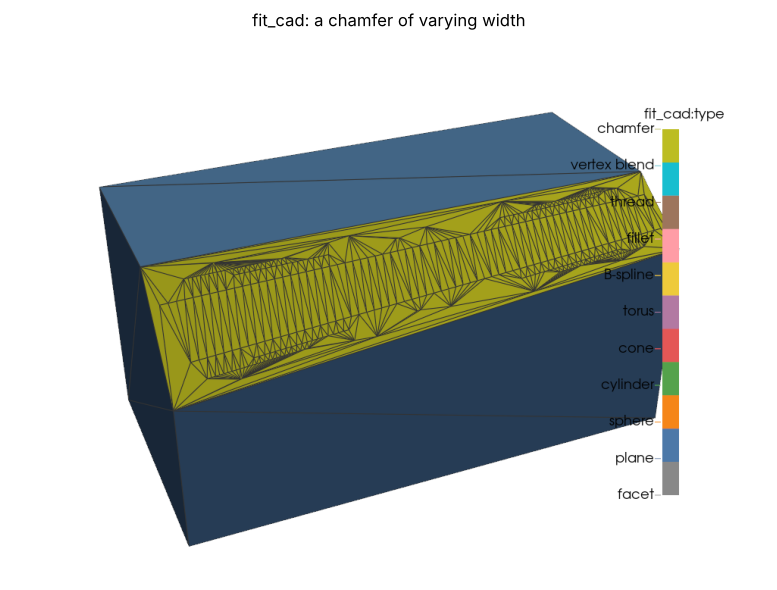

  a rounded box: conic and vertex blends: valid True, 26 faces -- chamfer 0, fillet 12 (conic 12), vertex blend 8, thread 0 (tapered 0), faceted 0; deviation 4.1e-03 (tolerance 6.9e-03)


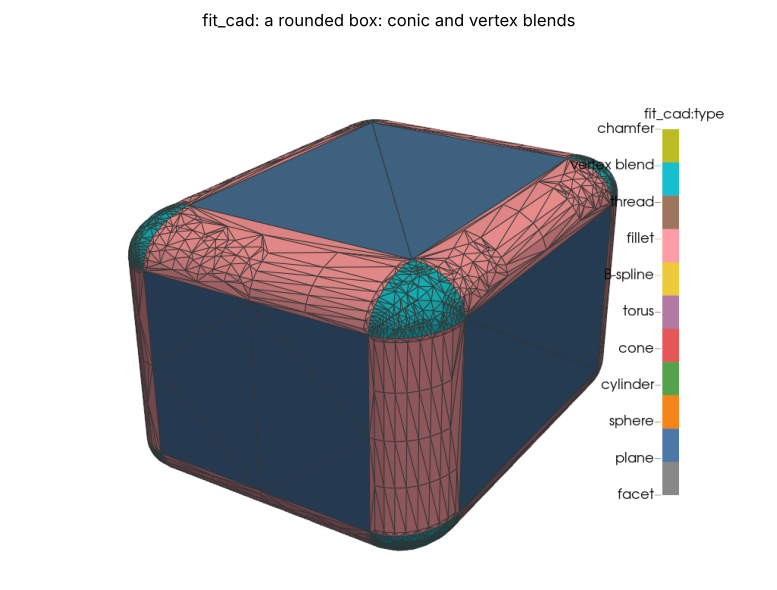

                        a tapered thread: valid True, 136 faces -- chamfer 0, fillet 0 (conic 0), vertex blend 0, thread 2 (tapered 2), faceted 128; deviation 3.4e-03 (tolerance 1.2e-02)


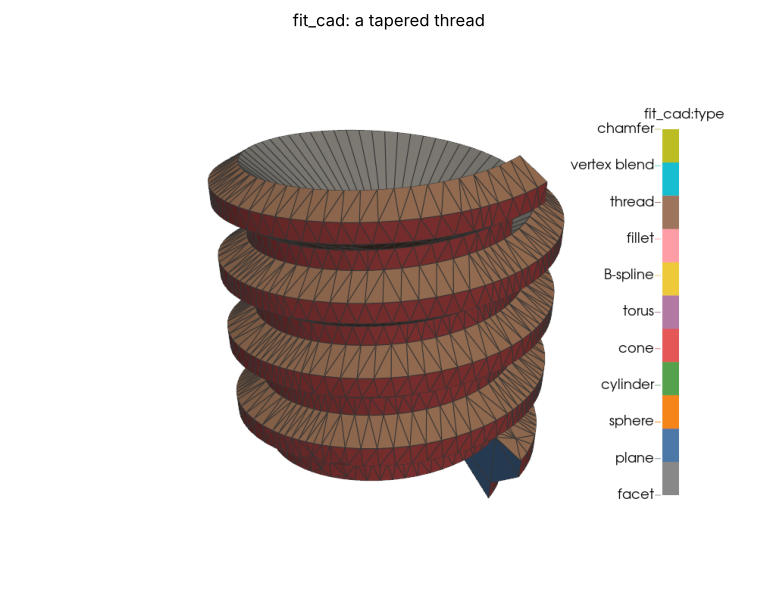

In [14]:
FEATURE_COLORS = TYPE_COLORS + ['#eeca3b', '#ff9da6', '#9d755d', '#17becf', '#bcbd22']
FEATURES = {**FEATURES, 9: 'vertex blend', 10: 'chamfer'}
# The labelled skins skip segment(); the thread is segmented by its creases alone.
cases = [('a chamfer of varying width', chamfered_block(), 'fit_cad_chamfer', (0.6, 1.4, 0.9)),
         ('a rounded box: conic and vertex blends', rounded_box(), 'fit_cad_vertex_blend', (1.0, -1.6, 0.9)),
         ('a tapered thread', mp.segment(tapered_thread_rod()), 'fit_cad_tapered_thread', (1.0, -1.6, 0.9))]
if has_occt():
    for title, skin, save, view in cases:
        fitted = mp.fit_primitives(skin, tolerance=1e-3)
        solid, cad = mp.fit_cad(fitted, return_report=True)
        print(f"{title:>40}: valid {cad['valid']}, {cad['num_faces']} faces -- "
              f"chamfer {cad['num_chamfer']}, fillet {cad['num_fillet']} (conic {cad['num_conic_blend']}), "
              f"vertex blend {cad['num_vertex_blend']}, thread {cad['num_helical']} "
              f"(tapered {cad['num_tapered_thread']}), faceted {cad['num_faceted_faces']}; "
              f"deviation {cad['max_deviation']:.1e} (tolerance {cad['tolerance']:.1e})")
        render(solid, f'fit_cad: {title}', scalars='fit_cad:type', cmap=FEATURE_COLORS,
               clim=[0, 10], annotations=FEATURES, save=save, view=view)
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON.')

## One face per surface: a part exported from CAD

An STL exported from CAD is tessellated straight from the part's faces: every point lies
exactly on a plane or a cylinder, and a rounded corner meets the flat sides it is tangent to
with no crease at all. Segmenting it by angles merges the rounded corner with both sides,
and no primitive fits that patch; writing it facet by facet gives a solid of hundreds of
triangles. `segment(method="primitive")` grows each patch only while one plane, cylinder,
cone, sphere or torus explains it -- the approach of stlToSolid and stl2curves -- so the
plate below, with a through-hole and one rounded corner, comes apart into its eight faces:
six planes, the hole and the fillet.

456 triangles
patches by angle: 6 -- by primitive: 8
fitted types: ['plane', 'plane', 'plane', 'cylinder', 'cylinder', 'plane', 'plane', 'plane']


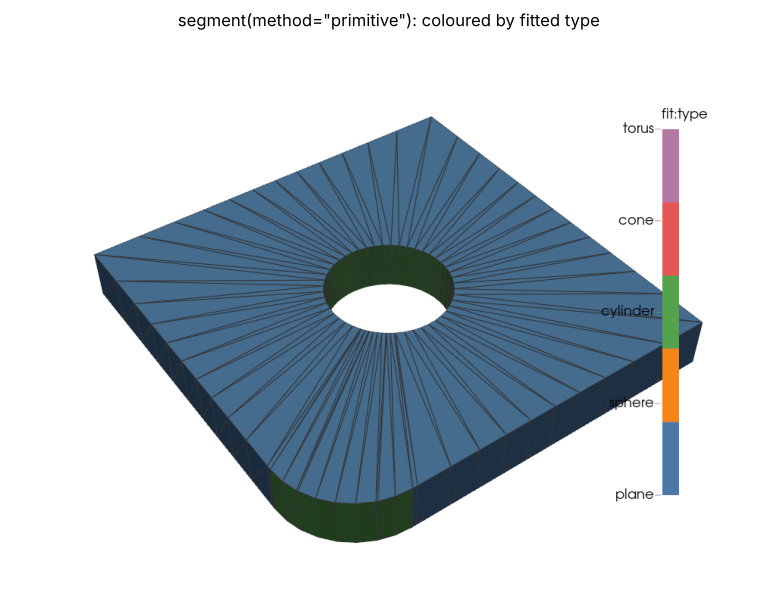

In [15]:
def filleted_plate(a=2.0, h=0.5, r=0.6, rc=0.8, n=48, k=8):
    '''The plate [-a, a]^2 x [0, h] with a hole of radius r and its corner (a, a) rounded by a
    quarter circle of radius rc, tessellated as a CAD exporter does: rings of vertices on the
    hole and the outline joined by strips, every vertex exactly on its surfaces.'''
    c = a - rc
    angles = {2.0 * np.pi * i / n for i in range(n)}
    angles |= {np.pi * (0.75 + 0.5 * j) for j in range(3)}  # the sharp corners
    for j in range(k + 1):  # along the fillet
        phi = 0.5 * np.pi * j / k
        angles.add(np.arctan2(c + rc * np.sin(phi), c + rc * np.cos(phi)))
    angles = sorted(angles)
    lo_t, hi_t = np.arctan2(c, a), np.arctan2(a, c)

    def outline(th):
        d = np.array([np.cos(th), np.sin(th)])
        if lo_t <= th <= hi_t:
            dc = d @ np.array([c, c])
            return (dc + np.sqrt(dc * dc - 2.0 * c * c + rc * rc)) * d
        return a / max(abs(d[0]), abs(d[1])) * d

    b, rings = Skin(), []
    for th in angles:
        d, o = np.array([np.cos(th), np.sin(th)]), outline(th)
        rings.append([b.add([r * d[0], r * d[1], z]) for z in (0.0, h)]
                     + [b.add([o[0], o[1], z]) for z in (0.0, h)])
    for i in range(len(rings)):
        (hb, ht, ob, ot), (hb2, ht2, ob2, ot2) = rings[i], rings[(i + 1) % len(rings)]
        mid = 0.5 * (angles[i] + angles[(i + 1) % len(rings)] + (2 * np.pi if i + 1 == len(rings) else 0))
        d = np.array([np.cos(mid), np.sin(mid), 0.0])
        for quad, out in (((ht, ot, ot2, ht2), [0, 0, 1]), ((hb, ob, ob2, hb2), [0, 0, -1]),
                          ((ob, ob2, ot2, ot), d), ((hb, hb2, ht2, ht), -d)):
            b.tri(quad[0], quad[1], quad[2], out)
            b.tri(quad[0], quad[2], quad[3], out)
    return b.mesh()


plate = filleted_plate()
print(len(plate.cells[0].data), 'triangles')
by_angle = mp.segment(plate, return_report=True)[1]['num_patches']
plate_seg, plate_report = mp.segment(plate, method='primitive', return_report=True)
print('patches by angle:', by_angle, '-- by primitive:', plate_report['num_patches'])
diag = float(np.linalg.norm(np.ptp(plate.points, axis=0)))
plate_fit = mp.fit_primitives(plate_seg, tolerance=1e-3 * diag, relative=False)
print('fitted types:', [TYPES[t] for t in plate_fit.field_data['fit:patch_type']])
render(plate_fit, 'segment(method="primitive"): coloured by fitted type', scalars='fit:type',
       cmap=TYPE_COLORS[1:], clim=[1, 5], annotations={i: TYPES[i] for i in range(1, 6)},
       save='skin_to_cad_plate_patches', view=(1.0, 1.4, 1.6))

The STEP the writer makes from it is eight faces -- six `PLANE`s, two
`CYLINDRICAL_SURFACE`s, with the hole as an inner loop of the top and bottom faces and
circles for its rims -- instead of one face per triangle. `fit_cad` runs the same chain on
the raw skin; without OpenCASCADE it is exactly this writer (`backend="native"`), and with
it the faces are also trimmed, sewn and checked. Read back through OpenCASCADE, the solid's
faces are the part's own.

faces= 'facet': {'ADVANCED_FACE': 456, 'PLANE': 456, 'CYLINDRICAL_SURFACE': 0, 'FACE_BOUND': 0, 'CIRCLE': 0, 'LINE': 684}
faces=  'auto': {'ADVANCED_FACE': 8, 'PLANE': 6, 'CYLINDRICAL_SURFACE': 2, 'FACE_BOUND': 5, 'CIRCLE': 4, 'LINE': 13}
fit_cad native: valid True, 8 faces (6 planes, 2 cylinders, 0 faceted), skin volume 7.36584, solid volume nan
fit_cad   occt: valid True, 8 faces (6 planes, 2 cylinders, 0 faceted), skin volume 7.36584, solid volume 7.36584
exact volume     : 7.36584


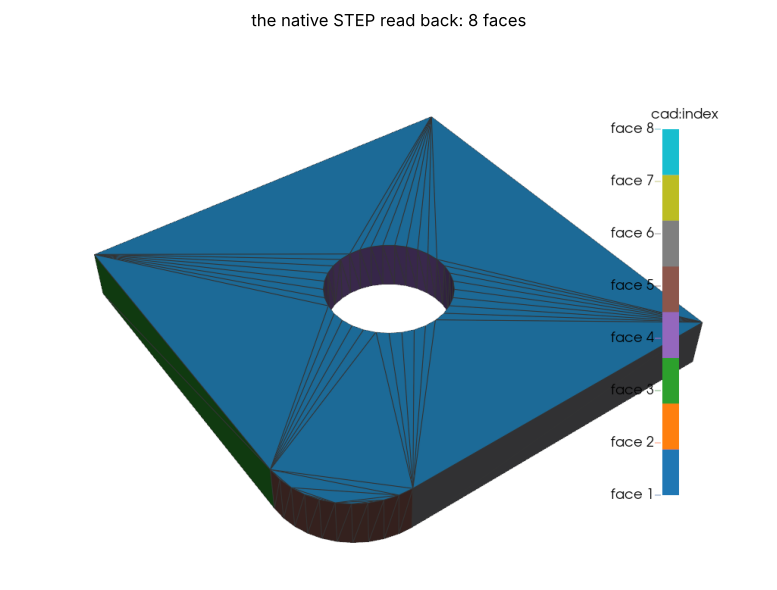

In [16]:
for faces in ('facet', 'auto'):
    path = os.path.join(TMP, f'plate_{faces}.step')
    mp.write(path, plate_fit, faces=faces)
    text = open(path).read()
    print(f'faces={faces!r:>8}:', {e: text.count('=' + e + '(') for e in
          ('ADVANCED_FACE', 'PLANE', 'CYLINDRICAL_SURFACE', 'FACE_BOUND', 'CIRCLE', 'LINE')})

for backend in ('native', 'occt') if has_occt() else ('native',):
    path = os.path.join(TMP, f'plate_{backend}.step')
    solid, cad = mp.fit_cad(plate, path, backend=backend, return_report=True)
    print(f'fit_cad {backend:>6}: valid {cad["valid"]}, {cad["num_faces"]} faces '
          f'({cad["num_plane"]} planes, {cad["num_cylinder"]} cylinders, '
          f'{cad["num_faceted_faces"]} faceted), skin volume {cad["skin_volume"]:.5f}, '
          f'solid volume {cad["volume"]:.5f}')  # NaN natively: no kernel measures it
print('exact volume     :', f'{(16 - (0.8 ** 2 - np.pi * 0.8 ** 2 / 4) - np.pi * 0.6 ** 2) * 0.5:.5f}')

if has_occt():
    back = mp.read(os.path.join(TMP, 'plate_native.step'))
    faces = int(np.max(back.cell_data['cad:index'][0])) + 1
    render(back, f'the native STEP read back: {faces} faces', scalars='cad:index',
           cmap='tab10', annotations={i: f'face {i + 1}' for i in range(faces)},
           save='skin_to_cad_plate_step', view=(1.0, 1.4, 1.6))
else:
    render(solid, 'fit_cad (native): the skin coloured by STEP face', scalars='fit_cad:face',
           cmap='tab10', save='skin_to_cad_plate_step', view=(1.0, 1.4, 1.6))

## Refining the patches first

Segmented by its creases alone, the noisy part has four patches: the wall, the fillet and
the shoulder are one, and no primitive explains it. `refine_patches` (v17.11.0) refines
the patches by a variational shape approximation over primitive proxies: it moves patch
boundaries onto the surfaces, splits a primitive out of a patch none explains by seeded
RANSAC and merges neighbours one primitive explains, then rewrites the fit table. See
[refine patches](../../doc/refine_patches.md). Two helpers draw meshes side by side,
coloured by a cell array, with `render`'s matplotlib fallback:

In [17]:
from matplotlib.colors import ListedColormap

PATCH_COLORS = ['#4c78a8', '#f58518', '#54a24b', '#e45756', '#b279a2', '#eeca3b', '#9d755d', '#17becf']


def snapshot(mesh, scalars, cmap, clim, annotations=None, categories=True, view=(1.0, -1.6, 0.9)):
    '''A PyVista image of a mesh coloured by a cell array, drawn as render() draws it.'''
    bar = {'title': scalars, 'vertical': True, 'position_x': 0.86, 'position_y': 0.15,
           'height': 0.7, 'width': 0.06, 'n_labels': 0 if annotations else 5}
    pl = pv.Plotter(off_screen=True, window_size=(900, 720))
    pl.add_mesh(to_grid(mesh), scalars=scalars, cmap=cmap, clim=clim, categories=categories,
                annotations=annotations, scalar_bar_args=bar, show_edges=True,
                edge_color='#333333', line_width=0.2)
    pl.view_vector(view, viewup=(0, 0, 1))
    pl.reset_camera()
    pl.camera.zoom(1.15)
    img = pl.screenshot(return_img=True)
    pl.close()
    return img


def render_row(meshes, titles, scalars, cmap, clim, annotations=None, categories=True, view=(1.0, -1.6, 0.9)):
    '''Meshes side by side; their cell centres, coloured, with matplotlib when GL is unavailable.'''
    fig, axes = plt.subplots(1, len(meshes), figsize=(7 * len(meshes), 5.6), squeeze=False)
    for ax, mesh, title in zip(axes[0], meshes, titles):
        try:
            ax.imshow(snapshot(mesh, scalars, cmap, clim, annotations, categories, view))
        except Exception as exc:  # pragma: no cover - head-less GL fallback
            print('PyVista render skipped:', exc)
            p = np.asarray(mesh.points)
            centres = np.concatenate([p[c.data].mean(axis=1) for c in mesh.cells])
            ax.scatter(centres[:, 0], centres[:, 2], s=2, c=np.concatenate(mesh.cell_data[scalars]),
                       cmap=ListedColormap(cmap) if isinstance(cmap, list) else cmap,
                       vmin=clim[0], vmax=clim[1])
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

Refine the creased, fitted part at `5e-4` of its diagonal, a tolerance just above the noise:

In [18]:
angle_fit = mp.fit_primitives(mp.segment(part), tolerance=2e-3)
refined, ref_report = mp.refine_patches(angle_fit, tolerance=5e-4, return_report=True)
print({k: ref_report[k] for k in ('num_patches', 'num_splits', 'num_merges', 'num_absorbed', 'stop')})
print(f"explained area: {ref_report['initial_explained_area_fraction']:.1%} before, "
      f"{ref_report['explained_area_fraction']:.1%} after")
for label, mesh in (('before', angle_fit), ('after', refined)):
    sizes = np.bincount(np.concatenate(mesh.cell_data['segment:patch'])).tolist()
    print(f'{label:>6}: patch sizes {sizes}, fitted {[TYPES[t] for t in mesh.field_data["fit:patch_type"]]}')

{'num_patches': 6, 'num_splits': 2, 'num_merges': 0, 'num_absorbed': 0, 'stop': 'unchanged'}
explained area: 37.6% before, 100.0% after
before: patch sizes [256, 384, 1216, 384], fitted ['plane', 'sphere', 'none', 'cone']
 after: patch sizes [256, 384, 512, 512, 192, 384], fitted ['plane', 'sphere', 'cylinder', 'torus', 'plane', 'cone']


The patches before and after, one colour per `segment:patch`:

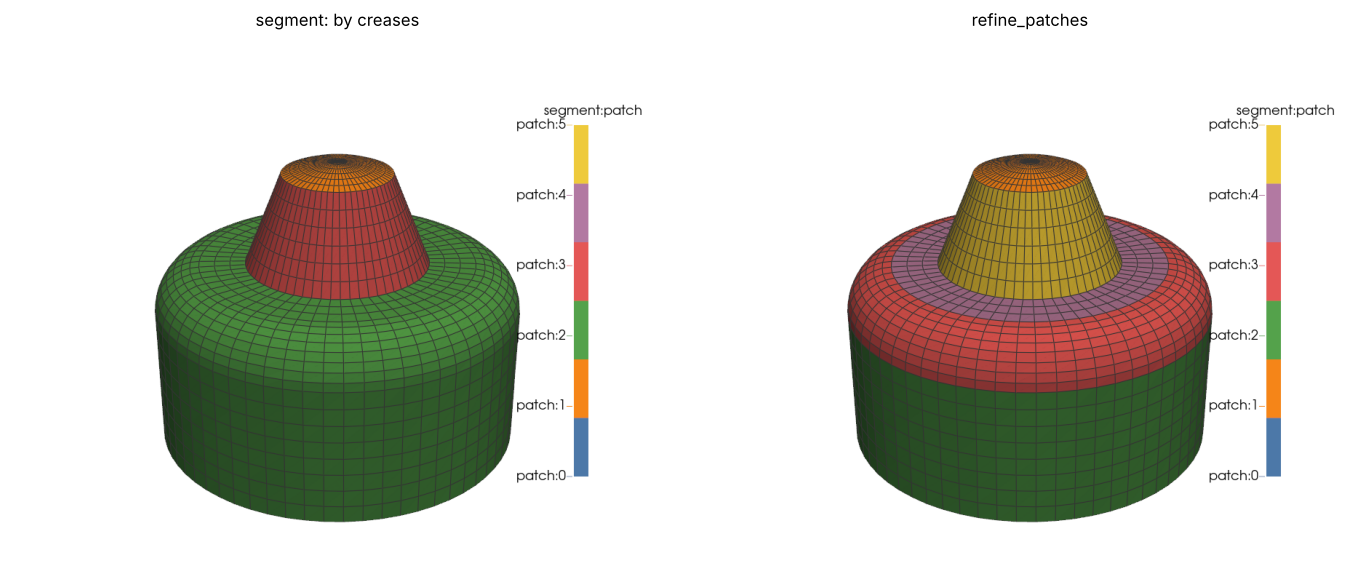

In [19]:
n = max(ref_report['num_patches'], 4)
render_row([angle_fit, refined], ['segment: by creases', 'refine_patches'], 'segment:patch',
           PATCH_COLORS[:n], [0, n - 1], annotations={k: f'patch:{k}' for k in range(n)})

## `fit_cad(refine_segmentation=True)`

`fit_cad` runs the same refinement itself when asked, builds the solid from the refined
patches and from the patches as given, and keeps the refined one unless the other is better
(`refinement_kept`). On the creased part the default leaves the merged patch as noisy facets;
refined at the default tolerance (`1e-3` of the diagonal) the wall takes in a ring of the
fillet and is demoted; at `5e-4` every surface is an analytic face. The three builds take
under a minute:

In [20]:
runs = {'default': {}, 'refined': {'refine_segmentation': True},
        'refined, 5e-4': {'refine_segmentation': True, 'refine_tolerance': 5e-4}}
solids = {}
BSPLINE_TYPES = {k: FEATURES[k] for k in range(7)}  # facet, the primitives, B-spline
if has_occt():
    print(f"{'':>14} {'faces':>6} {'faceted':>8} {'demoted':>8} {'max dev':>9}  refinement_kept")
    for label, options in runs.items():
        solids[label], cad = mp.fit_cad(angle_fit, return_report=True, **options)
        print(f"{label:>14} {cad['num_faces']:>6} {cad['num_faceted_faces']:>8} {cad['num_demoted']:>8} "
              f"{cad['max_deviation']:9.2e}  {cad.get('refinement_kept', '-')}")
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON.')

                faces  faceted  demoted   max dev  refinement_kept


       default   2419     2415        0  7.10e-03  -


       refined   1077     1072        1  5.14e-03  True


 refined, 5e-4      6        0        0  5.21e-03  True


The default and the refined solid, coloured by `fit_cad:type`, facets grey:

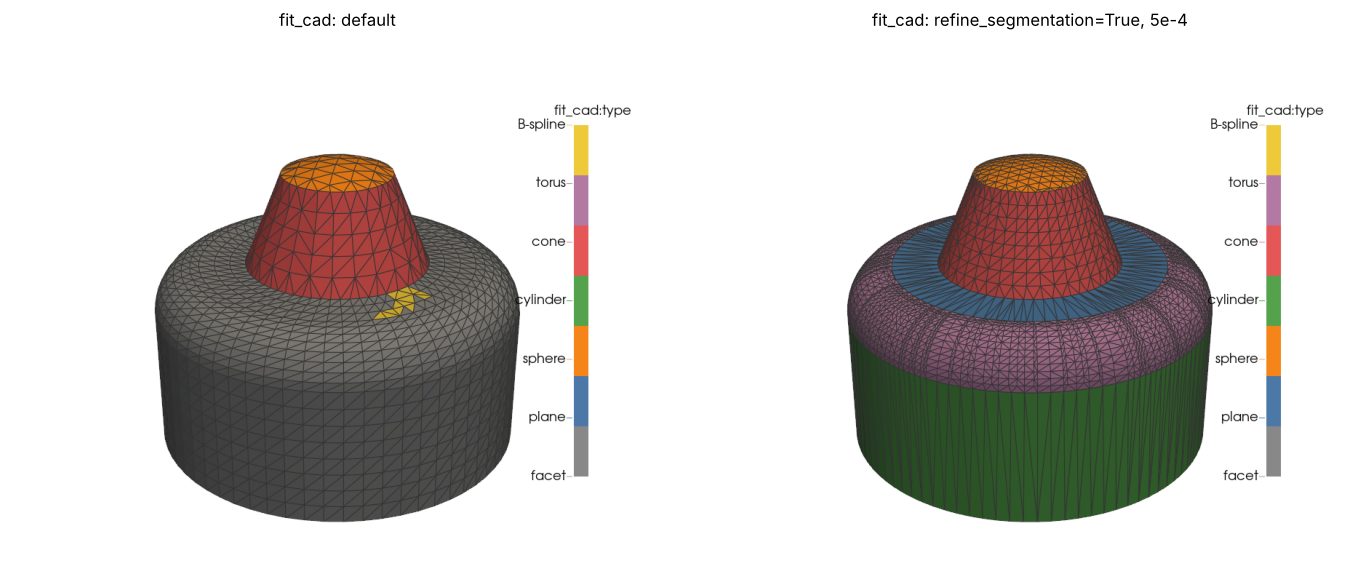

In [21]:
if solids:
    render_row([solids['default'], solids['refined, 5e-4']],
               ['fit_cad: default', 'fit_cad: refine_segmentation=True, 5e-4'],
               'fit_cad:type', FEATURE_COLORS[:7], [0, 6], annotations=BSPLINE_TYPES)

## General freeform faces

The capped wavy band from above, with the grid freeform fit held to four control points a
side (`freeform_max_control=4`), leaves both halves of its wall as nearly six thousand
facets. `freeform_general=True` (v17.11.0) gives such a patch a second try: a least-squares
conformal map to the plane, then a least-squares cubic B-spline whose parameters are
corrected and whose knots are refined until it reaches the tolerance. See
[general freeform faces](../../doc/fit_cad.md#general-freeform-faces). Both builds take
about half a minute:

In [22]:
band = mp.fit_primitives(mp.segment(wavy_capped()))
bands = {}
if has_occt():
    for label, options in (('grid fit', {}), ('general fit', {'freeform_general': True})):
        bands[label], cad = mp.fit_cad(band, freeform_max_control=4, return_report=True, **options)
        print(f"{label:>12}: valid {cad['valid']}, {cad['num_faces']} faces -- B-spline {cad['num_bspline']} "
              f"(general {cad.get('num_freeform_general', 0)}, average poles "
              f"{cad.get('avg_freeform_poles', 0):.0f}), faceted {cad['num_faceted_faces']}; "
              f"deviation {cad['max_deviation']:.1e} (tolerance {cad['tolerance']:.1e})")
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON.')

    grid fit: valid True, 5858 faces -- B-spline 0 (general 0, average poles 0), faceted 5856; deviation 5.6e-14 (tolerance 8.5e-03)


 general fit: valid True, 4 faces -- B-spline 2 (general 2, average poles 81), faceted 0; deviation 3.5e-03 (tolerance 8.5e-03)


Before and after, coloured by `fit_cad:type`, facets grey:

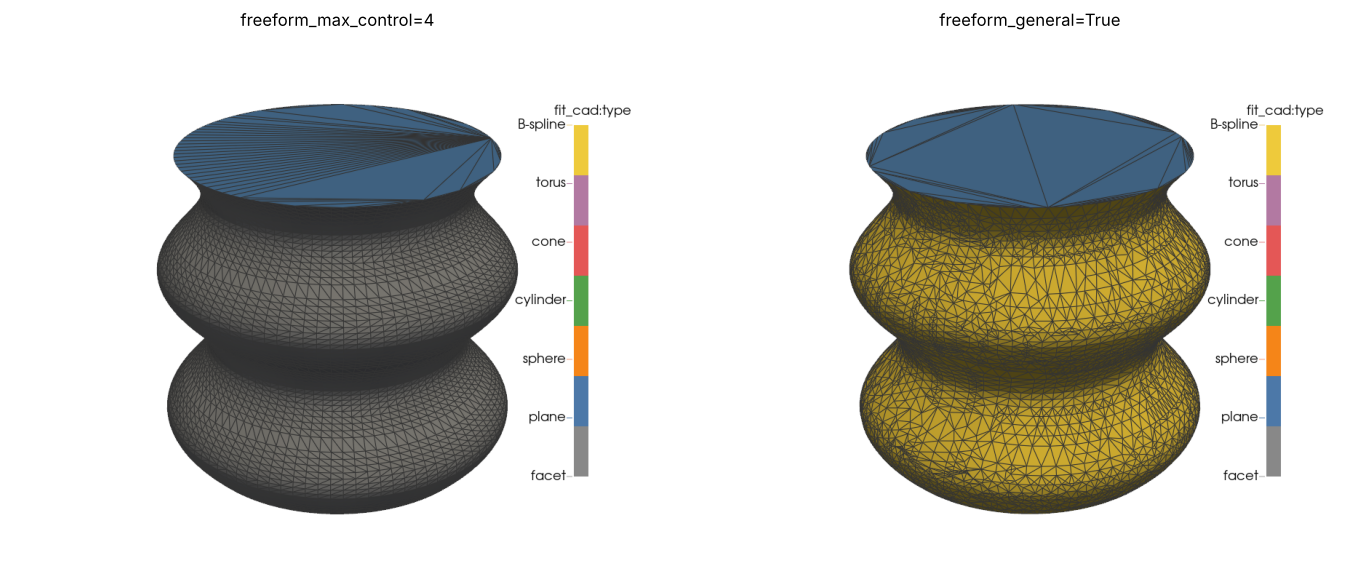

In [23]:
if bands:
    render_row([bands['grid fit'], bands['general fit']],
               ['freeform_max_control=4', 'freeform_general=True'],
               'fit_cad:type', FEATURE_COLORS[:7], [0, 6], annotations=BSPLINE_TYPES)

## Snapped junctions and per-face deviation

Two more options check the solid closer (v17.11.0). `snap_junctions=True` places each
vertex where analytic faces meet by a least-squares solve on their tangent planes, and
`face_deviation=True` measures the two-sided distance between every face and the skin: the
field data `fit_cad:face_hausdorff` holds each face's two one-sided maxima (in `fit_cad:face`
order) and `fit_cad:face_rms` their RMS. Every report also says whether each shell is
`closed`. See
[edges, sewing and validation options](../../doc/fit_cad.md#edges-sewing-and-validation-options).
On the curvature-segmented turned part from above:

In [24]:
checked = None
if has_occt():
    checked, cad = mp.fit_cad(fit, snap_junctions=True, face_deviation=True, return_report=True)
    print({k: cad[k] for k in ('valid', 'closed', 'num_faces', 'num_snapped_junctions')})
    print(f"hausdorff max {cad['hausdorff_max']:.2e}, rms {cad['hausdorff_rms']:.2e}"
          f" (tolerance {cad['tolerance']:.2e})")
    print('face  solid->skin  skin->solid      rms')
    for face, ((a, b), rms) in enumerate(zip(checked.field_data['fit_cad:face_hausdorff'],
                                             checked.field_data['fit_cad:face_rms'])):
        print(f'{face:>4} {a:12.2e} {b:12.2e} {rms:8.2e}')
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON.')

{'valid': True, 'closed': True, 'num_faces': 6, 'num_snapped_junctions': 10}
hausdorff max 8.66e-03, rms 2.42e-03 (tolerance 3.51e-02)
face  solid->skin  skin->solid      rms
   0     2.82e-03     5.21e-03 8.40e-04
   1     6.55e-03     6.10e-03 1.92e-03
   2     5.99e-03     8.66e-03 2.07e-03
   3     1.08e-03     1.16e-03 4.13e-04
   4     7.09e-03     7.71e-03 3.56e-03
   5     5.84e-03     6.26e-03 3.47e-03


Each face's larger one-sided distance, mapped onto its cells through `fit_cad:face`:

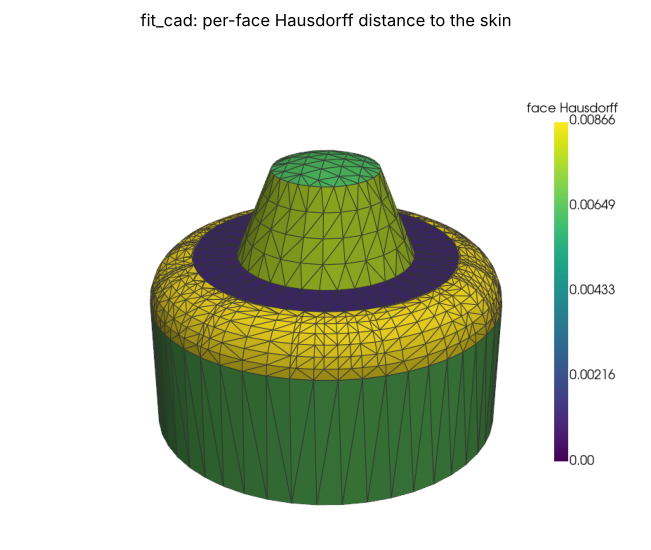

In [25]:
if checked is not None:
    per_face = checked.field_data['fit_cad:face_hausdorff'].max(axis=1)
    checked.cell_data['face Hausdorff'] = [per_face[faces] for faces in checked.cell_data['fit_cad:face']]
    render_row([checked], ['fit_cad: per-face Hausdorff distance to the skin'], 'face Hausdorff',
               'viridis', [0.0, float(per_face.max())], categories=False)

## Constrained primitives

`fit_primitives` fits each patch on its own, so the wall, the fillet, the cone and the dome of the noisy part each get an axis of their own, a little off the others, and the base and the shoulder are almost, not exactly, perpendicular to them. `constrain_primitives=True` fits them together before the faces are built: the coaxial ones share one axis exactly, the planes take it as their normal, and each change is kept only where its patch still passes its fit. A solid whose constraints would demote more patches than the unconstrained one is replaced by the unconstrained solid. It works in both backends; the native one returns the skin with the constrained `fit:patch_*` table, which the plot below reads: each primitive's axis (a plane's normal, a sphere's centre) against the shared one, before and after.

         fitted one by one: 6 faces, 0 demoted {}
 constrain_primitives=True: 6 faces, 0 demoted {'num_constrained_primitives': 6, 'num_constraint_groups': 2}


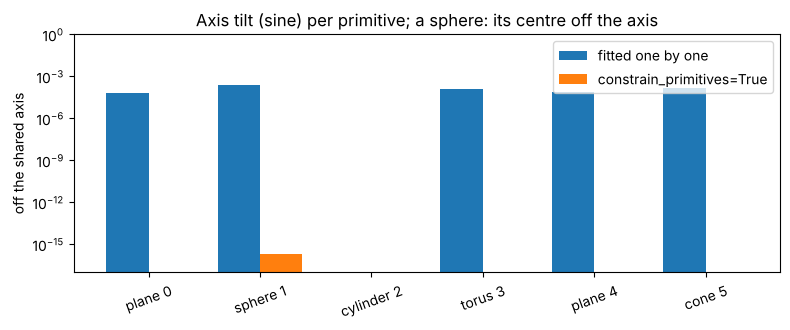

In [26]:
TILTED = {1: 'plane', 2: 'sphere', 3: 'cylinder', 4: 'cone', 5: 'torus'}


def axis_spread(mesh):
    """Per fitted patch: its type and how far its axis (a plane's normal) turns from the
    first axial patch's, in radians; a sphere's centre's distance from that axis instead."""
    fd = mesh.field_data
    types, params = np.asarray(fd['fit:patch_type']), np.asarray(fd['fit:patch_params'])
    first = next(i for i, t in enumerate(types) if t in (3, 4, 5))
    x0, d0 = params[first, :3], params[first, 3:6]
    out = []
    for t, p in zip(types, params):
        if t == 2:
            v = p[:3] - x0
            out.append((TILTED[t], np.linalg.norm(v - v.dot(d0) * d0)))
        elif t in TILTED:
            out.append((TILTED[t], np.sqrt(max(0.0, 1.0 - min(1.0, abs(p[3:6].dot(d0))) ** 2))))
    return out


spreads = {}
for label, on in (('fitted one by one', False), ('constrain_primitives=True', True)):
    native, rep = mp.fit_cad(fit, backend='native', constrain_primitives=on, return_report=True)
    spreads[label] = axis_spread(native)
    extra = {k: rep[k] for k in ('num_constrained_primitives', 'num_constraint_groups') if k in rep}
    print(f"{label:>26}: {rep['num_faces']} faces, {rep['num_demoted']} demoted", extra)

fig, ax = plt.subplots(figsize=(8, 3.4))
names = [f'{n} {i}' for i, (n, _) in enumerate(spreads['fitted one by one'])]
width = 0.38
for k, (label, rows) in enumerate(spreads.items()):
    vals = [max(v, 1e-17) for _, v in rows]
    ax.bar(np.arange(len(vals)) + (k - 0.5) * width, vals, width, label=label)
ax.set_yscale('log')
ax.set_ylim(1e-17, 1)
ax.set_xticks(range(len(names)), names, rotation=20)
ax.set_ylabel('off the shared axis')
ax.set_title('Axis tilt (sine) per primitive; a sphere: its centre off the axis')
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()

## Freeform modes: fewer facets

`freeform_mode` (v17.12.0) changes what happens to a patch no primitive or feature explains. `"legacy"`, the default, is everything above; `"adaptive"` fits each such patch as a B-spline face (cut into discs along its topology first, on a parametrisation ladder, with refine, re-parametrise and split rungs before it gives up), and the native backend writes those faces too, so this needs no OpenCASCADE; `"network"` lays each freeform region out in quads and fits them as B-spline patches that share their edge curves exactly, G1 across them; `"auto"` tries adaptive faces first and the network for what they leave. Every patch that still ends as facets says why.

Two skins: a box whose top is a monkey saddle, and a closed organic blob (an icosphere pushed out by smooth lobes).

In [27]:
def heightfield_box(n=24, height=None):
    '''The unit cube's skin as triangles, its top lifted by height(x, y) and its sides with it.'''
    pts, idx, tris = [], {}, []

    def add(p):
        key = tuple(np.round(p, 12))
        if key not in idx:
            idx[key] = len(pts)
            pts.append(p)
        return idx[key]

    g = np.linspace(0.0, 1.0, n + 1)
    for a, b, c, w, flip in ((0, 1, 2, 0.0, False), (0, 1, 2, 1.0, True), (1, 2, 0, 0.0, False),
                             (1, 2, 0, 1.0, True), (2, 0, 1, 0.0, False), (2, 0, 1, 1.0, True)):
        for i in range(n):
            for j in range(n):
                q = []
                for di, dj in ((0, 0), (1, 0), (1, 1), (0, 1)):
                    p = np.zeros(3)
                    p[a], p[b], p[c] = g[i + di], g[j + dj], w
                    q.append(add(p))
                q = q[::-1] if flip else q
                tris += [[q[0], q[1], q[2]], [q[0], q[2], q[3]]]
    P = np.array(pts)
    # The sides follow the top in proportion, so a top lowered by more than a row's height does
    # not fold their top row over.
    up = P[:, 2] > 0.0
    P[up, 2] *= 1.0 + height(P[up, 0], P[up, 1])
    return mp.Mesh(P, [('triangle', np.array(tris, dtype=np.int64))])


saddle = heightfield_box(24, lambda x, y: 0.15 * ((2 * x - 1) ** 3 - 3 * (2 * x - 1) * (2 * y - 1) ** 2))
sphere = mp.icosa_sphere(subdivisions=4)
sp = np.asarray(sphere.points, dtype=float)
blob = mp.Mesh(sp * (1.0 + 0.25 * np.sin(2 * sp[:, 0]) * np.cos(3 * sp[:, 1]) + 0.15 * sp[:, 2] ** 3)[:, None],
               sphere.cells)


def facet_area_fraction(out):
    '''The share of the skin's area written as facets (fit_cad:type 0).'''
    p = np.asarray(out.points, dtype=float)
    tri = np.asarray(out.cells[0].data)
    area = 0.5 * np.linalg.norm(np.cross(p[tri[:, 1]] - p[tri[:, 0]], p[tri[:, 2]] - p[tri[:, 0]]), axis=1)
    return float(area[np.asarray(out.cell_data['fit_cad:type'][0]) == 0].sum() / area.sum())


MODES = ('legacy', 'adaptive', 'network', 'auto')
freeform_runs = {}
print(f"{'':>11} {'mode':>9} {'faceted area':>13} {'faces':>6} {'adaptive':>9} {'network':>8} {'EVs':>4} {'G1 deg':>7}")
for name, skin in (('saddle box', saddle), ('blob', blob)):
    pts = np.asarray(skin.points)
    tol = 2e-3 * float(np.linalg.norm(pts.max(0) - pts.min(0)))
    fitted = mp.fit_primitives(mp.segment(skin), tolerance=tol, relative=False)
    for mode in MODES:
        out, rep = mp.fit_cad(fitted, backend='native', tolerance=tol, freeform_mode=mode, return_report=True)
        freeform_runs[name, mode] = (out, rep)
        extra = (f"{rep['num_freeform_adaptive']:>9} {rep['num_network_patches']:>8} "
                 f"{rep['num_extraordinary_vertices']:>4} {rep['max_g1_angle_deg']:>7.2f}") if mode != 'legacy' else ''
        print(f"{name:>11} {mode:>9} {facet_area_fraction(out):>13.4f} {rep['num_faces']:>6} {extra}")

                 mode  faceted area  faces  adaptive  network  EVs  G1 deg


 saddle box    legacy        0.1948   1157 
 saddle box  adaptive        0.0000      6         1        0    0    0.00


 saddle box   network        0.0000     21         0       16    0    1.21
 saddle box      auto        0.0000      6         1        0    0    0.00


       blob    legacy        1.0000   5120 


       blob  adaptive        0.0000      2         2        0    0    0.00


       blob   network        0.0000      6         4        2    8    0.03


       blob      auto        0.0000      2         2        0    0    0.00


The faceted area by mode. The report's `facet_area_fraction` is the same number (it is only reported outside `legacy`, so the legacy column is measured from `fit_cad:type`):

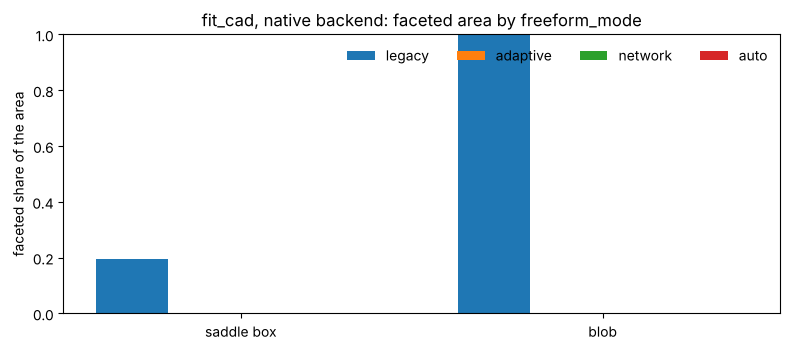

In [28]:
fig, ax = plt.subplots(figsize=(8, 3.6))
width = 0.2
for k, mode in enumerate(MODES):
    vals = [facet_area_fraction(freeform_runs[name, mode][0]) for name in ('saddle box', 'blob')]
    ax.bar(np.arange(2) + (k - 1.5) * width, vals, width, label=mode)
ax.set_xticks(range(2), ['saddle box', 'blob'])
ax.set_ylabel('faceted share of the area')
ax.set_ylim(0, 1)
ax.legend(ncol=4, frameon=False)
ax.set_title('fit_cad, native backend: faceted area by freeform_mode')
plt.tight_layout()
plt.show()

The saddle box, legacy and network, coloured by `fit_cad:type`: in `legacy` the native backend writes the saddle as facets (grey); in `network` it is a grid of B-spline patches (`B_SPLINE_SURFACE_WITH_KNOTS` in the STEP file) whose shared edges are the same curves on both sides.

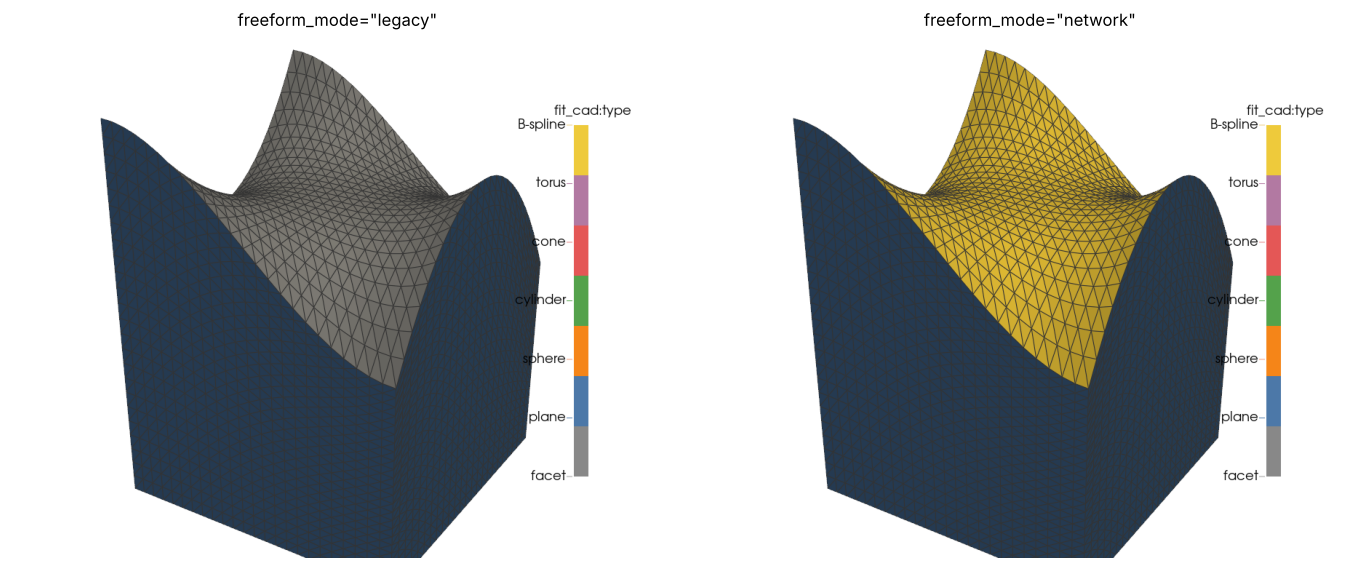

In [29]:
render_row([freeform_runs['saddle box', 'legacy'][0], freeform_runs['saddle box', 'network'][0]],
           ['freeform_mode="legacy"', 'freeform_mode="network"'],
           'fit_cad:type', FEATURE_COLORS[:7], [0, 6], annotations=BSPLINE_TYPES)

The network's layout on the saddle, one colour per patch (`fit_cad:patch`), and on the blob, where the extraordinary vertices sit at the corners of the O-grids its two caps are laid out in; a patch the network cannot fit within the tolerance (or that folds) falls back to an adaptive face, so the blob still has no facets:

saddle box: 16 network patches, 0 adaptive faces, 24 shared edges, 0 extraordinary vertices, largest G1 angle 1.21 deg
blob: 2 network patches, 4 adaptive faces, 12 shared edges, 8 extraordinary vertices, largest G1 angle 0.03 deg


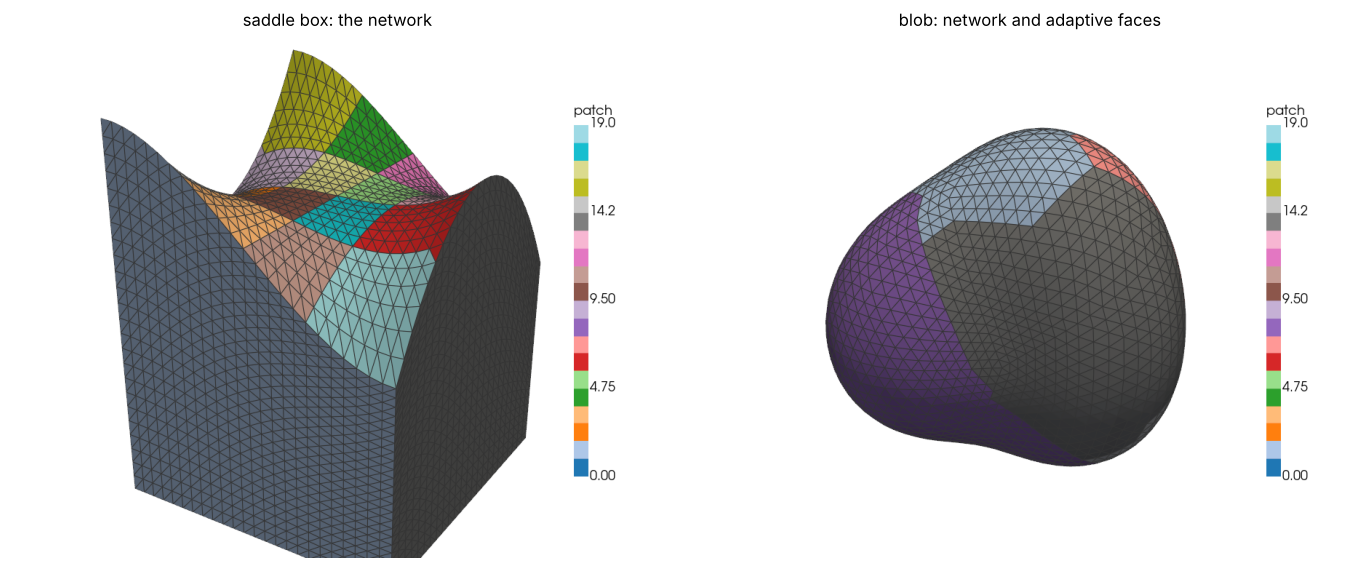

In [30]:
shown = []
for name in ('saddle box', 'blob'):
    out, rep = freeform_runs[name, 'network']
    _, compact = np.unique(np.asarray(out.cell_data['fit_cad:patch'][0]), return_inverse=True)
    mesh = mp.Mesh(out.points, out.cells)
    mesh.cell_data['patch'] = [((compact * 7) % 20).astype(np.int64)]
    shown.append(mesh)
    print(f"{name}: {rep['num_network_patches']} network patches, {rep['num_freeform_adaptive']} adaptive faces, "
          f"{rep['num_network_edges']} shared edges, {rep['num_extraordinary_vertices']} extraordinary vertices, "
          f"largest G1 angle {rep['max_g1_angle_deg']:.2f} deg")
render_row(shown, ['saddle box: the network', 'blob: network and adaptive faces'], 'patch', 'tab20', [0, 19],
           categories=False)

With OpenCASCADE the network's patches are faces of the checked solid too: each patch keeps its fitted surface, the edge between two network patches is the piece of the curve both took their boundary from (no surface intersection), and under `"auto"` an adaptive face the B-rep checks reject is rebuilt in the network of its region before it becomes facets. Here the saddle box with the OpenCASCADE backend, by face type:


OpenCASCADE: valid True, 16 network patches, 24 shared edges, largest G1 angle 2.26 deg, faceted area 0.000


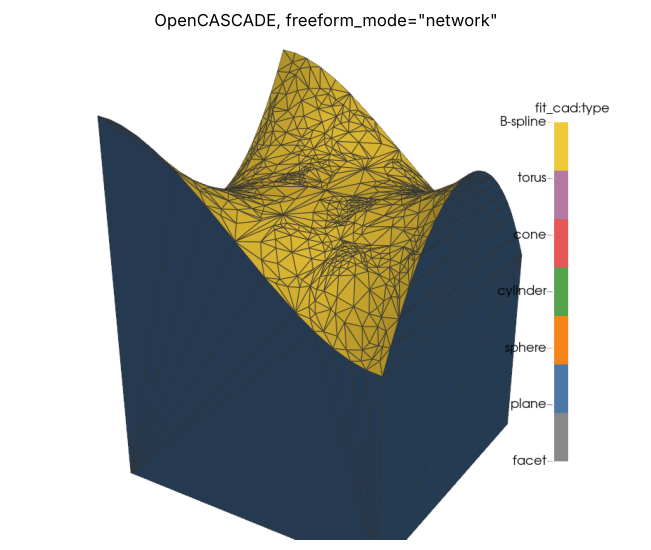

In [31]:
from meshioplusplus._fit_cad import has_occt

if has_occt():
    fitted_saddle = mp.fit_primitives(mp.segment(saddle), tolerance=2e-3)
    occt_solid, occt_rep = mp.fit_cad(fitted_saddle, freeform_mode='network', return_report=True)
    print(f"OpenCASCADE: valid {occt_rep['valid']}, {occt_rep['num_network_patches']} network patches, "
          f"{occt_rep['num_network_edges']} shared edges, largest G1 angle {occt_rep['max_g1_angle_deg']:.2f} deg, "
          f"faceted area {occt_rep['facet_area_fraction']:.3f}")
    render_row([occt_solid], ['OpenCASCADE, freeform_mode="network"'], 'fit_cad:type', FEATURE_COLORS[:7], [0, 6],
               annotations=BSPLINE_TYPES)
else:
    print('this build has no OpenCASCADE')


## Re-segmentation: a crease the segmentation missed

A segmentation can merge two faces across a crease it smoothed over somewhere along its length. No single surface fits the result, and halving it only moves the crease into smaller pieces. `resegment_rounds` (default 2) is the last rung of the ladder: a patch whose adaptive fit misses across sharp edges is cut along them first, and a region still left as facets after the adaptive faces and the network is cut in two by variational shape approximation on its normals, its pieces grown across gentle edges before sharp ones, then fitted again. Here a car-hood box with its top and one side merged into one patch:

resegment_rounds=0: faceted area 0.2691, 519 faces, 2 adaptive, 0 cut(s)


resegment_rounds=2: faceted area 0.0052, 22 faces, 4 adaptive, 1 cut(s)


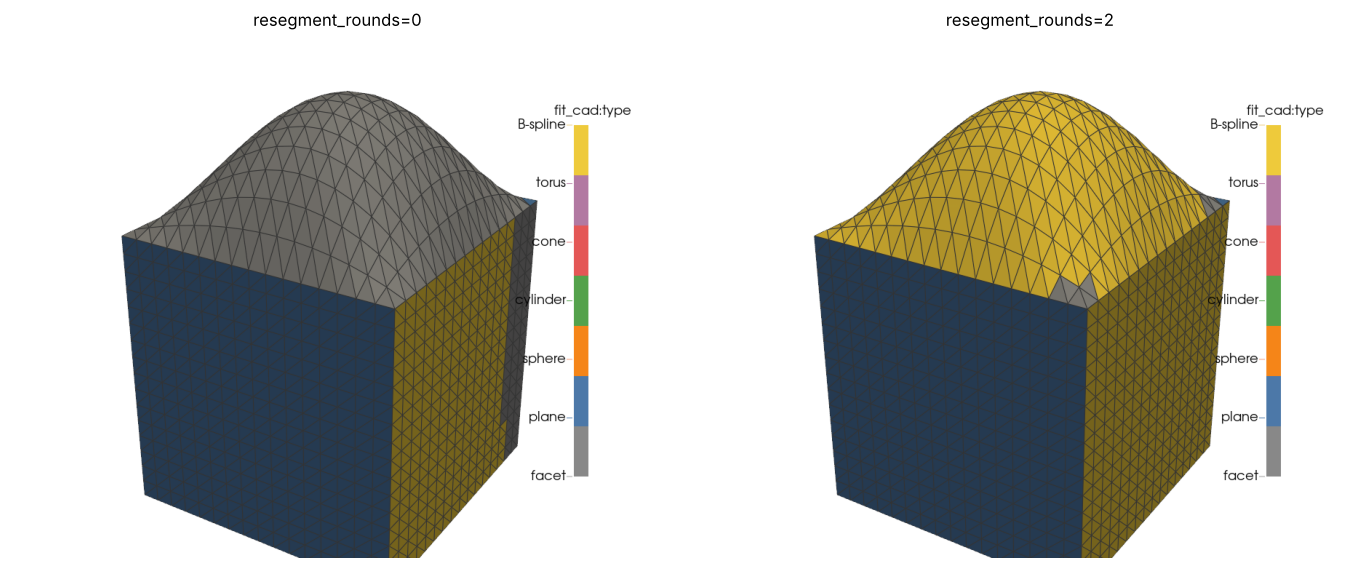

In [32]:
def merged_side(fitted):
    '''The fitted box with its planar side at x = 0 merged into its freeform (type 0) patch.'''
    pts = np.asarray(fitted.points)
    lo = pts[:, 0].min()
    ids = np.asarray(fitted.field_data['fit:patch_id'])
    types = np.asarray(fitted.field_data['fit:patch_type'])
    freeform = int(ids[types == 0][0])
    side, labels = None, []
    for block, data in zip(fitted.cells, fitted.cell_data['segment:patch']):
        lab = np.asarray(data, dtype=np.int64).copy()
        on = np.all(pts[block.data][:, :, 0] == lo, axis=1)
        if on.any():
            side = int(lab[on][0])
        lab[on] = freeform
        labels.append(lab)
    out = mp.Mesh(fitted.points, fitted.cells, cell_data={**fitted.cell_data, 'segment:patch': labels},
                  field_data=dict(fitted.field_data))
    keep = ids != side
    for key in ('fit:patch_id', 'fit:patch_type', 'fit:patch_params', 'fit:patch_tolerance'):
        out.field_data[key] = np.asarray(fitted.field_data[key])[keep]
    return out


hood = heightfield_box(16, lambda x, y: 0.35 * 16 * x * (1 - x) * y * (1 - y) * (1 + 0.4 * x))
hp = np.asarray(hood.points)
hood_tol = 2e-3 * float(np.linalg.norm(hp.max(0) - hp.min(0)))
merged = merged_side(mp.fit_primitives(mp.segment(hood), tolerance=hood_tol, relative=False))
reseg = {}
for rounds in (0, 2):
    out, rep = mp.fit_cad(merged, backend='native', tolerance=hood_tol, freeform_mode='adaptive',
                          resegment_rounds=rounds, return_report=True)
    reseg[rounds] = out
    print(f"resegment_rounds={rounds}: faceted area {rep['facet_area_fraction']:.4f}, {rep['num_faces']} faces, "
          f"{rep['num_freeform_adaptive']} adaptive, {rep['num_resegmented']} cut(s)")
render_row([reseg[0], reseg[2]], ['resegment_rounds=0', 'resegment_rounds=2'], 'fit_cad:type', FEATURE_COLORS[:7],
           [0, 6], annotations=BSPLINE_TYPES)

## A surface with two handles

A double torus: the zero level of `((x^2 + y^2)^2 - x^2 + y^2)^2 + 4 z^2 - 0.02`, contoured on a tetrahedral grid into triangles and quads. The layout first cuts the region along its handles into discs; the network's patches that fit are faces, and those that miss become adaptive faces, so the network leaves less area as facets than the adaptive faces alone:

adaptive: faceted area 0.1648, 0 network patches, 34 adaptive faces


 network: faceted area 0.0298, 7 network patches, 66 adaptive faces


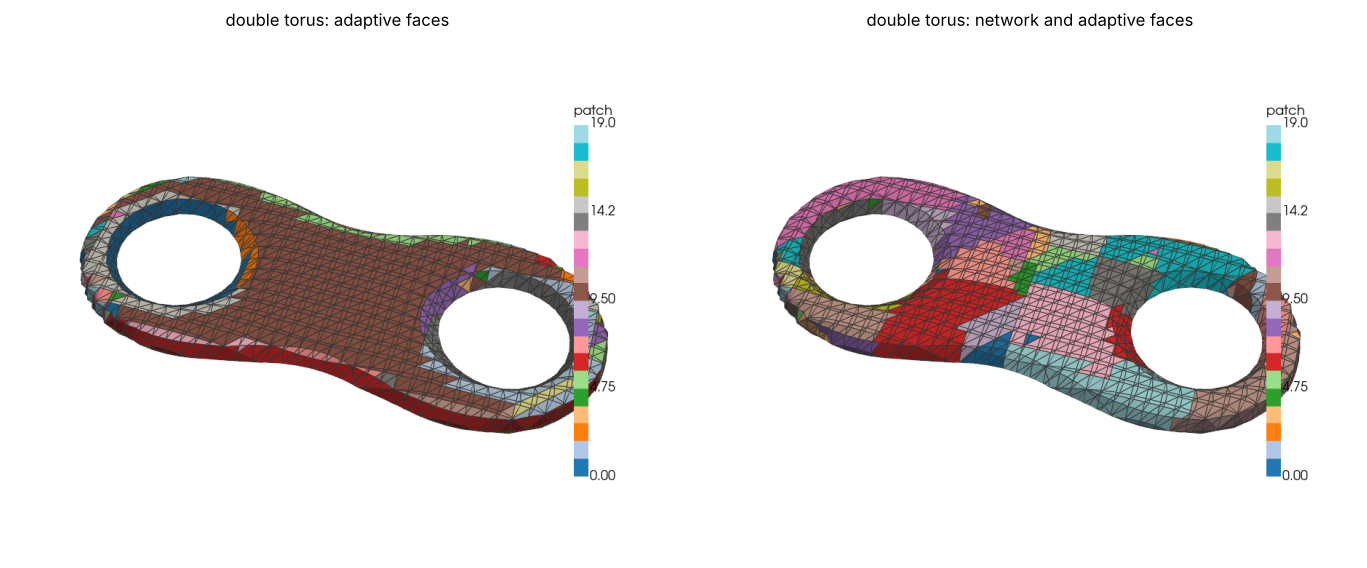

In [33]:
# The grid is placed so that no node lands on the level set (a crossing there would leave a hole).
grid = mp.box(dims=(48, 24, 16), size=(2.6206, 1.3094, 0.8122), origin=(-1.3117, -0.6531, -0.4073), cell_type='tetra')
g = np.asarray(grid.points, dtype=float)
lem = (g[:, 0] ** 2 + g[:, 1] ** 2) ** 2 - g[:, 0] ** 2 + g[:, 1] ** 2
grid.point_data['f'] = lem ** 2 + 4.0 * g[:, 2] ** 2 - 0.02
double_torus = mp.isosurface(grid, 'f', 0.0)
dp = np.asarray(double_torus.points)
dt_tol = 2e-3 * float(np.linalg.norm(dp.max(0) - dp.min(0)))
dt_fitted = mp.fit_primitives(mp.segment(double_torus), tolerance=dt_tol, relative=False)
genus = {}
for mode in ('adaptive', 'network'):
    out, rep = mp.fit_cad(dt_fitted, backend='native', tolerance=dt_tol, freeform_mode=mode, return_report=True)
    genus[mode] = out
    print(f"{mode:>8}: faceted area {rep['facet_area_fraction']:.4f}, {rep['num_network_patches']} network patches, "
          f"{rep['num_freeform_adaptive']} adaptive faces")
shown = []
for mode in ('adaptive', 'network'):
    out = genus[mode]
    labels = [np.asarray(a) for a in out.cell_data['fit_cad:patch']]  # one array per block (triangles, quads)
    _, compact = np.unique(np.concatenate(labels), return_inverse=True)
    split = np.cumsum([len(a) for a in labels])[:-1]
    mesh = mp.Mesh(out.points, out.cells)
    mesh.cell_data['patch'] = [((c * 7) % 20).astype(np.int64) for c in np.split(compact, split)]
    shown.append(mesh)
render_row(shown, ['double torus: adaptive faces', 'double torus: network and adaptive faces'], 'patch', 'tab20',
           [0, 19], categories=False, view=(0.3, -1.0, 1.4))

## An extraordinary vertex up close

Where three or five patches meet, `extraordinary_vertex` chooses the continuity: `"g0"` leaves the vertex alone, `"g1x"` (the default) puts the first ring of poles round it in a common tangent plane and smooths the ring; where that does worse next to the vertices than `"g0"`, the network keeps `"g0"`. A cube cage refined by Catmull-Clark to its limit surface has eight such vertices of valence 3 in its layout. Its network, as the native backend returns it (trimmed NURBS faces in `info["brep"]`), is sampled by `cad_json.sample` (no CAD kernel involved) and drawn with the software rasterizer (`render_image`) close to one of those vertices, in zebra stripes: bands of the surface normal's component along one direction, as reflection lines show a car body. Where two patches meet with a tangent break, the stripes jump across their shared edge; the largest such angle is the report's `max_g1_angle_deg`, which in `"g0"` leaves out the samples next to the vertices.

extraordinary_vertex='g0': 40 network patches, 8 extraordinary vertices, largest G1 angle 3.13 deg


extraordinary_vertex='g1x': 40 network patches, 8 extraordinary vertices, largest G1 angle 4.05 deg


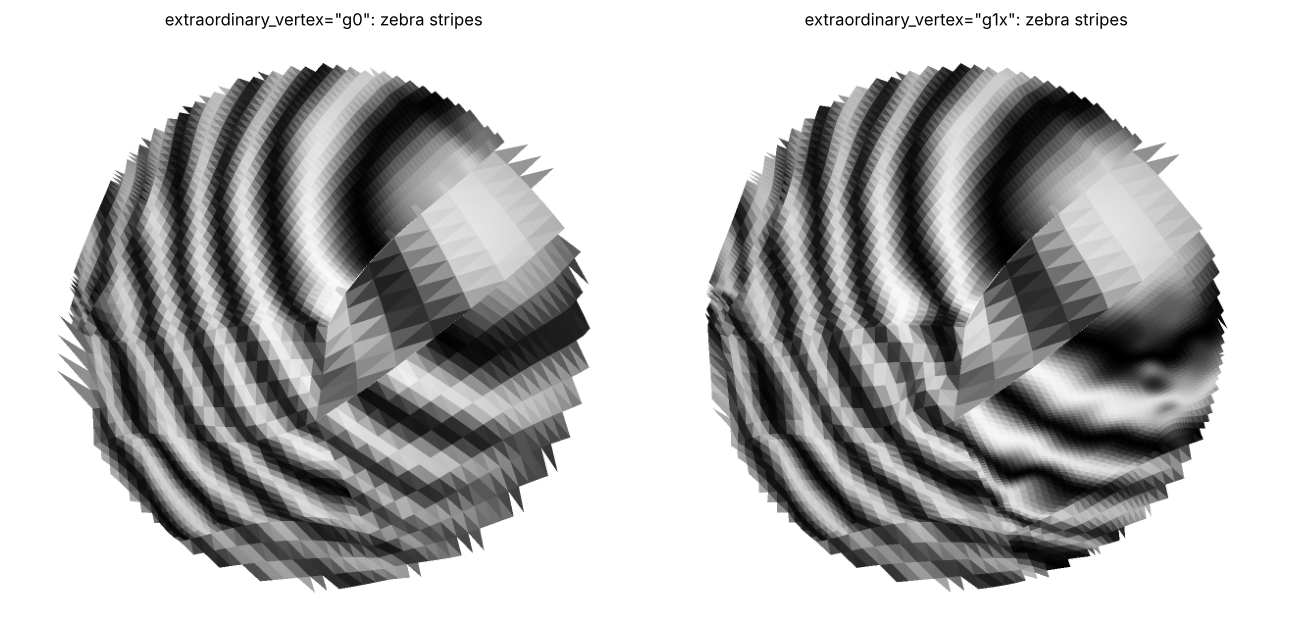

In [34]:
def ev_location(out, towards):
    '''The point where three or five network patches meet (fit_cad:patch) nearest the direction towards.'''
    tri = np.asarray(out.cells[0].data)
    patch = np.asarray(out.cell_data['fit_cad:patch'][0])
    around = {}
    for t, p in enumerate(patch):
        for v in tri[t]:
            around.setdefault(int(v), set()).add(int(p))
    pts = np.asarray(out.points)
    d = np.asarray(towards, dtype=float) / np.linalg.norm(towards)
    best = max((v for v in around if len(around[v]) in (3, 5)),
               key=lambda v: pts[v] @ d / np.linalg.norm(pts[v]))
    return pts[best]


def sampled_triangles(sampled, weld):
    '''The sampled faces' cubic Lagrange quads as triangles on all their nodes, points welded across faces.'''
    q = np.asarray(sampled.points, dtype=float)
    cells = np.concatenate([np.asarray(b.data) for b in sampled.cells])
    # A cubic Lagrange quad's 4 x 4 nodes in VTK order, as a grid [i][j]; its 3 x 3 sub-quads.
    grid = [[0, 10, 11, 3], [4, 12, 14, 8], [5, 13, 15, 9], [1, 6, 7, 2]]
    sub = [(grid[i][j], grid[i + 1][j], grid[i + 1][j + 1], grid[i][j + 1]) for i in range(3) for j in range(3)]
    quads = np.concatenate([cells[:, list(s)] for s in sub])
    _, first, inv = np.unique(np.round(q / weld).astype(np.int64), axis=0, return_index=True, return_inverse=True)
    tri = inv.ravel()[np.concatenate([quads[:, [0, 1, 2]], quads[:, [0, 2, 3]]])]
    ok = (tri[:, 0] != tri[:, 1]) & (tri[:, 1] != tri[:, 2]) & (tri[:, 0] != tri[:, 2])
    return mp.Mesh(q[first], [('triangle', tri[ok])])


def zebra(mesh, centre, radius, bands=9.0):
    '''The triangles within radius of centre, turned so a camera on +z looks at centre, with zebra stripes
    of the point normals as point data.'''
    p = np.asarray(mesh.points, dtype=float)
    tri = np.asarray(mesh.cells[0].data)
    n = np.cross(p[tri[:, 1]] - p[tri[:, 0]], p[tri[:, 2]] - p[tri[:, 0]])
    pn = np.zeros_like(p)
    for k in range(3):
        np.add.at(pn, tri[:, k], n)
    pn /= np.maximum(np.linalg.norm(pn, axis=1, keepdims=True), 1e-300)
    # A rotation taking the direction from the model's centre (the origin) to `centre` onto +z.
    z = centre / np.linalg.norm(centre)
    x = np.cross([0.0, 0.0, 1.0] if abs(z[2]) < 0.9 else [1.0, 0.0, 0.0], z)
    x /= np.linalg.norm(x)
    rot = np.stack([x, np.cross(z, x), z])
    keep = np.linalg.norm(p[tri].mean(axis=1) - centre, axis=1) < radius
    used, local = np.unique(tri[keep], return_inverse=True)
    out = mp.Mesh((p[used] - centre) @ rot.T, [('triangle', local.reshape(-1, 3))])
    d = rot.T @ np.array([0.45, 0.3, 0.84])
    out.point_data['zebra'] = 0.5 + 0.5 * np.cos(2.0 * np.pi * bands * (pn[used] @ d))
    return out


def catmull_clark(points, faces, levels):
    '''Catmull-Clark subdivision of a closed quad mesh, `levels` times.'''
    P, F = np.asarray(points, dtype=float), np.asarray(faces, dtype=np.int64)
    for _ in range(levels):
        nv, nf = len(P), len(F)
        fp = P[F].mean(axis=1)
        e = np.stack([F, np.roll(F, -1, axis=1)], axis=2).reshape(-1, 2)
        key = np.sort(e, axis=1)
        uniq, eid = np.unique(key, axis=0, return_inverse=True)
        eid = eid.ravel().reshape(nf, 4)
        ef = np.zeros((len(uniq), 3))
        np.add.at(ef, eid.ravel(), np.repeat(fp, 4, axis=0))
        ep = (P[uniq[:, 0]] + P[uniq[:, 1]] + ef) / 4.0  # ef: the sum of its two faces' points
        # Vertices: (Q + 2 R + (n - 3) P) / n.
        n = np.bincount(F.ravel(), minlength=nv).astype(float)
        Q = np.zeros((nv, 3))
        np.add.at(Q, F.ravel(), np.repeat(fp, 4, axis=0))
        Q /= n[:, None]
        R = np.zeros((nv, 3))
        mids = 0.5 * (P[uniq[:, 0]] + P[uniq[:, 1]])
        np.add.at(R, uniq[:, 0], mids)
        np.add.at(R, uniq[:, 1], mids)
        R /= n[:, None]
        V = (Q + 2.0 * R + (n[:, None] - 3.0) * P) / n[:, None]
        P = np.vstack([V, fp, ep])
        f_id = nv + np.arange(nf)
        e_id = nv + nf + eid
        newF = []
        for k in range(4):
            newF.append(np.stack([F[:, k], e_id[:, k], f_id, e_id[:, (k + 3) % 4]], axis=1))
        F = np.concatenate(newF)
    # The limit positions: (n^2 P + 4 sum(edge neighbours) + sum(diagonals)) / (n (n + 5)).
    n = np.bincount(F.ravel(), minlength=len(P)).astype(float)
    acc = n[:, None] ** 2 * P
    for k in range(4):
        v, e1, d, e2 = F[:, k], F[:, (k + 1) % 4], F[:, (k + 2) % 4], F[:, (k + 3) % 4]
        np.add.at(acc, v, 2.0 * (P[e1] + P[e2]) + P[d])
    return acc / (n * (n + 5.0))[:, None], F


cube_pts = [[-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1], [-1, -1, 1], [1, -1, 1], [1, 1, 1], [-1, 1, 1]]
cube_faces = [[0, 3, 2, 1], [4, 5, 6, 7], [0, 1, 5, 4], [1, 2, 6, 5], [2, 3, 7, 6], [3, 0, 4, 7]]
cp, cf = catmull_clark(cube_pts, cube_faces, 4)
cage = mp.Mesh(cp, [('triangle', np.concatenate([cf[:, [0, 1, 2]], cf[:, [0, 2, 3]]]))])


cage_pts = np.asarray(cage.points)
cage_diag = float(np.linalg.norm(cage_pts.max(0) - cage_pts.min(0)))
cage_tol = 2e-3 * cage_diag
cage_fitted = mp.fit_primitives(mp.segment(cage), tolerance=cage_tol, relative=False)
closeups = {}
for ev in ('g0', 'g1x'):
    out, rep = mp.fit_cad(cage_fitted, backend='native', tolerance=cage_tol, freeform_mode='network',
                          extraordinary_vertex=ev, return_report=True)
    print(f"extraordinary_vertex={ev!r}: {rep['num_network_patches']} network patches, "
          f"{rep['num_extraordinary_vertices']} extraordinary vertices, largest G1 angle {rep['max_g1_angle_deg']:.2f} deg")
    closeups[ev] = out

centre = ev_location(closeups['g1x'], (1.0, 1.0, 1.0))  # the one nearest the direction (1, 1, 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
for ax, ev in zip(axes, ('g0', 'g1x')):
    sampled = mp.cad_json.sample(closeups[ev].info['brep'], subdivisions=2, edges=False)
    near = zebra(sampled_triangles(sampled, 0.05 * cage_tol), centre, 0.22 * cage_diag)
    try:
        ax.imshow(mp.render_image(near, 640, 600, color_by='zebra', cmap='grey', vmin=0.0, vmax=1.0, view='+z',
                                  shading='smooth', supersample=2, background=(255, 255, 255, 255)))
    except Exception as exc:  # pragma: no cover - no compiled core
        print('render_image skipped:', exc)
        q = np.asarray(near.points)
        ax.scatter(q[:, 0], q[:, 1], s=2, c=near.point_data['zebra'], cmap='gray')
    ax.set_title(f'extraordinary_vertex="{ev}": zebra stripes')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Every demotion has a reason

Held to `1e-5` of the diagonal -- far below the facets' own chordal error -- no freeform face can pass, and each record in `faces` says why (`fit_cad:face_table` carries the same rows as field data):

In [35]:
pts = np.asarray(saddle.points)
tight = 1e-5 * float(np.linalg.norm(pts.max(0) - pts.min(0)))
_, strict = mp.fit_cad(mp.fit_primitives(mp.segment(saddle), tolerance=2e-3), backend='native',
                       tolerance=tight, freeform_mode='adaptive', return_report=True)
from collections import Counter

print(f"faceted area {strict['facet_area_fraction']:.3f}, escalations {strict['num_escalations']}")
print('reasons:', Counter(f['demotion_reason'] for f in strict['faces'] if f['kind'] in (0, 6)).most_common())
tried = [f for f in strict['faces'] if f['kind'] in (0, 6) and f['param_method'] != 'none']
print(f"{'patch':>5} {'kind':>4} {'param':>10} {'poles':>6} {'steps':>5} {'max dist':>9}  reason")
for f in tried[:8]:
        print(f"{f['patch']:>5} {f['kind']:>4} {f['param_method']:>10} {f['num_ctrl']:>6} "
              f"{f['escalation_steps']:>5} {f['max_dist']:>9.2e}  {f['demotion_reason']}")

faceted area 0.195, escalations 879
reasons: [('too_small', 44), ('budget_exceeded', 18), ('hausdorff_exceeded', 8), ('non_disc', 3)]
patch kind      param  poles steps  max dist  reason
   73    0 mean_value      0    19  1.62e-10  hausdorff_exceeded
   74    0 mean_value      0    19  1.75e-07  hausdorff_exceeded
   75    0 mean_value      0    19  4.93e-10  hausdorff_exceeded
   76    0 mean_value      0    19  2.25e-05  budget_exceeded
   77    0      plane      0    19  1.53e-04  non_disc
   78    0 mean_value      0    19  4.60e-04  budget_exceeded
   79    0 mean_value      0    19  8.82e-04  budget_exceeded
   80    0 mean_value      0    19  6.07e-04  budget_exceeded
